# Adjustability Results

In [1]:
suppressWarnings(suppressPackageStartupMessages({
  library(arrow)
  library(tidyverse)
  library(ggthemes)
  library(ggrepel)
  library(patchwork)
  library(IRdisplay)
}))

options(repr.plot.width = 14, repr.plot.height = 6, repr.plot.res = 150)

ROOT  <- if (dir.exists(file.path(getwd(), "data"))) getwd() else dirname(getwd())
DATA  <- file.path(ROOT, "data")
PLOTS <- file.path(ROOT, "results", "plots")
dir.create(PLOTS, recursive = TRUE, showWarnings = FALSE)

FT_THEME <- theme_fivethirtyeight() +
  theme(axis.title        = element_text(),
        axis.text         = element_text(size = 10),
        panel.background  = element_rect(fill = "white", color = NA),
        plot.background   = element_rect(fill = "white", color = NA),
        legend.background = element_rect(fill = "white", color = NA),
        strip.text        = element_text(size = 12, face = "bold"),
        plot.title        = element_text(size = 16, face = "bold"))

plot_path <- function(name) {
  sub <- if (startsWith(name, "adjustability")) "adjustability"
         else if (startsWith(name, "repertoire"))   "repertoire"
         else "predictiveness"
  d <- file.path(PLOTS, sub)
  dir.create(d, recursive = TRUE, showWarnings = FALSE)
  file.path(d, name)
}

In [2]:
adj <- read_parquet(file.path(DATA, "adjustability.parquet"))
cf  <- read_parquet(file.path(DATA, "adjustability_value.parquet"))

n_units_trait <- nrow(distinct(adj, batter_id, batter_stand))
n_swings_val  <- sum(cf$n_swings)

cat("=== Data section ===\n")
cat(sprintf("Trait (adjustability.parquet):       %5d units           [expect 471]\n", n_units_trait))
cat(sprintf("Value (adjustability_value.parquet): %5d units  %s swings  [expect 466 / 553,459]\n",
            nrow(cf), format(n_swings_val, big.mark = ",")))

=== Data section ===


Trait (adjustability.parquet):         471 units           [expect 471]


Value (adjustability_value.parquet):   466 units  553,459 swings  [expect 466 / 553,459]


## Adjustability leaderboard 

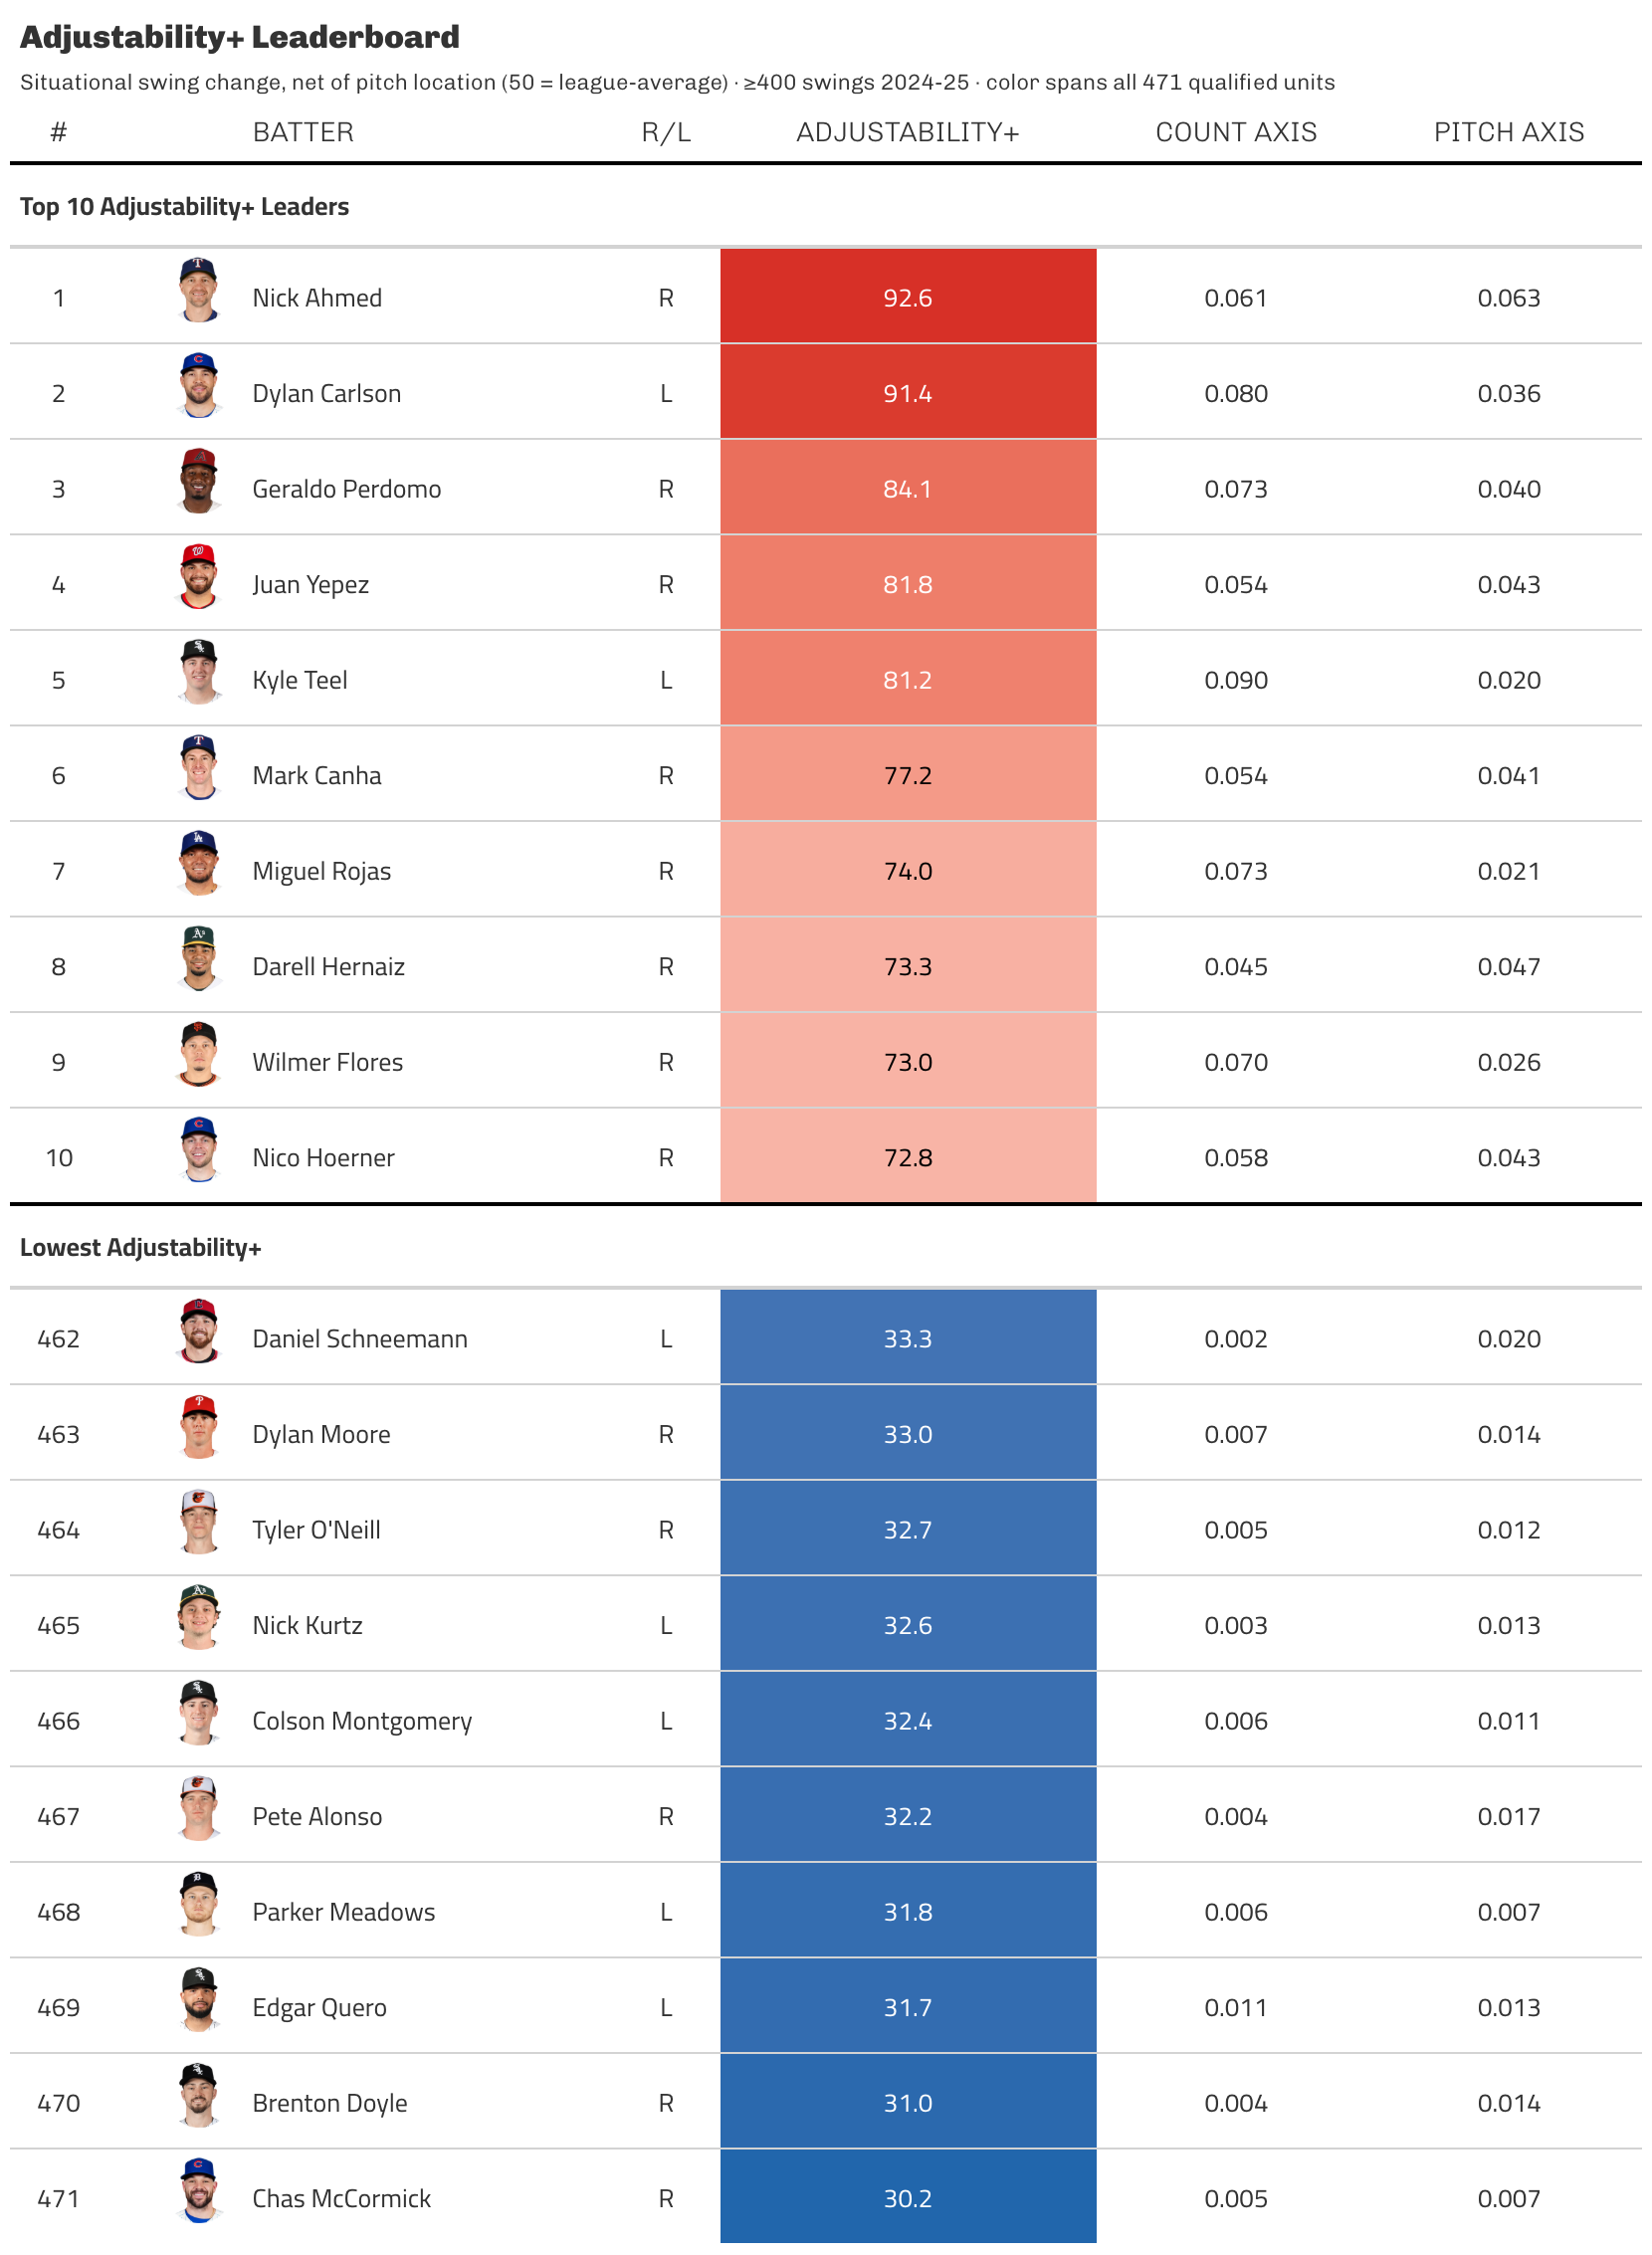

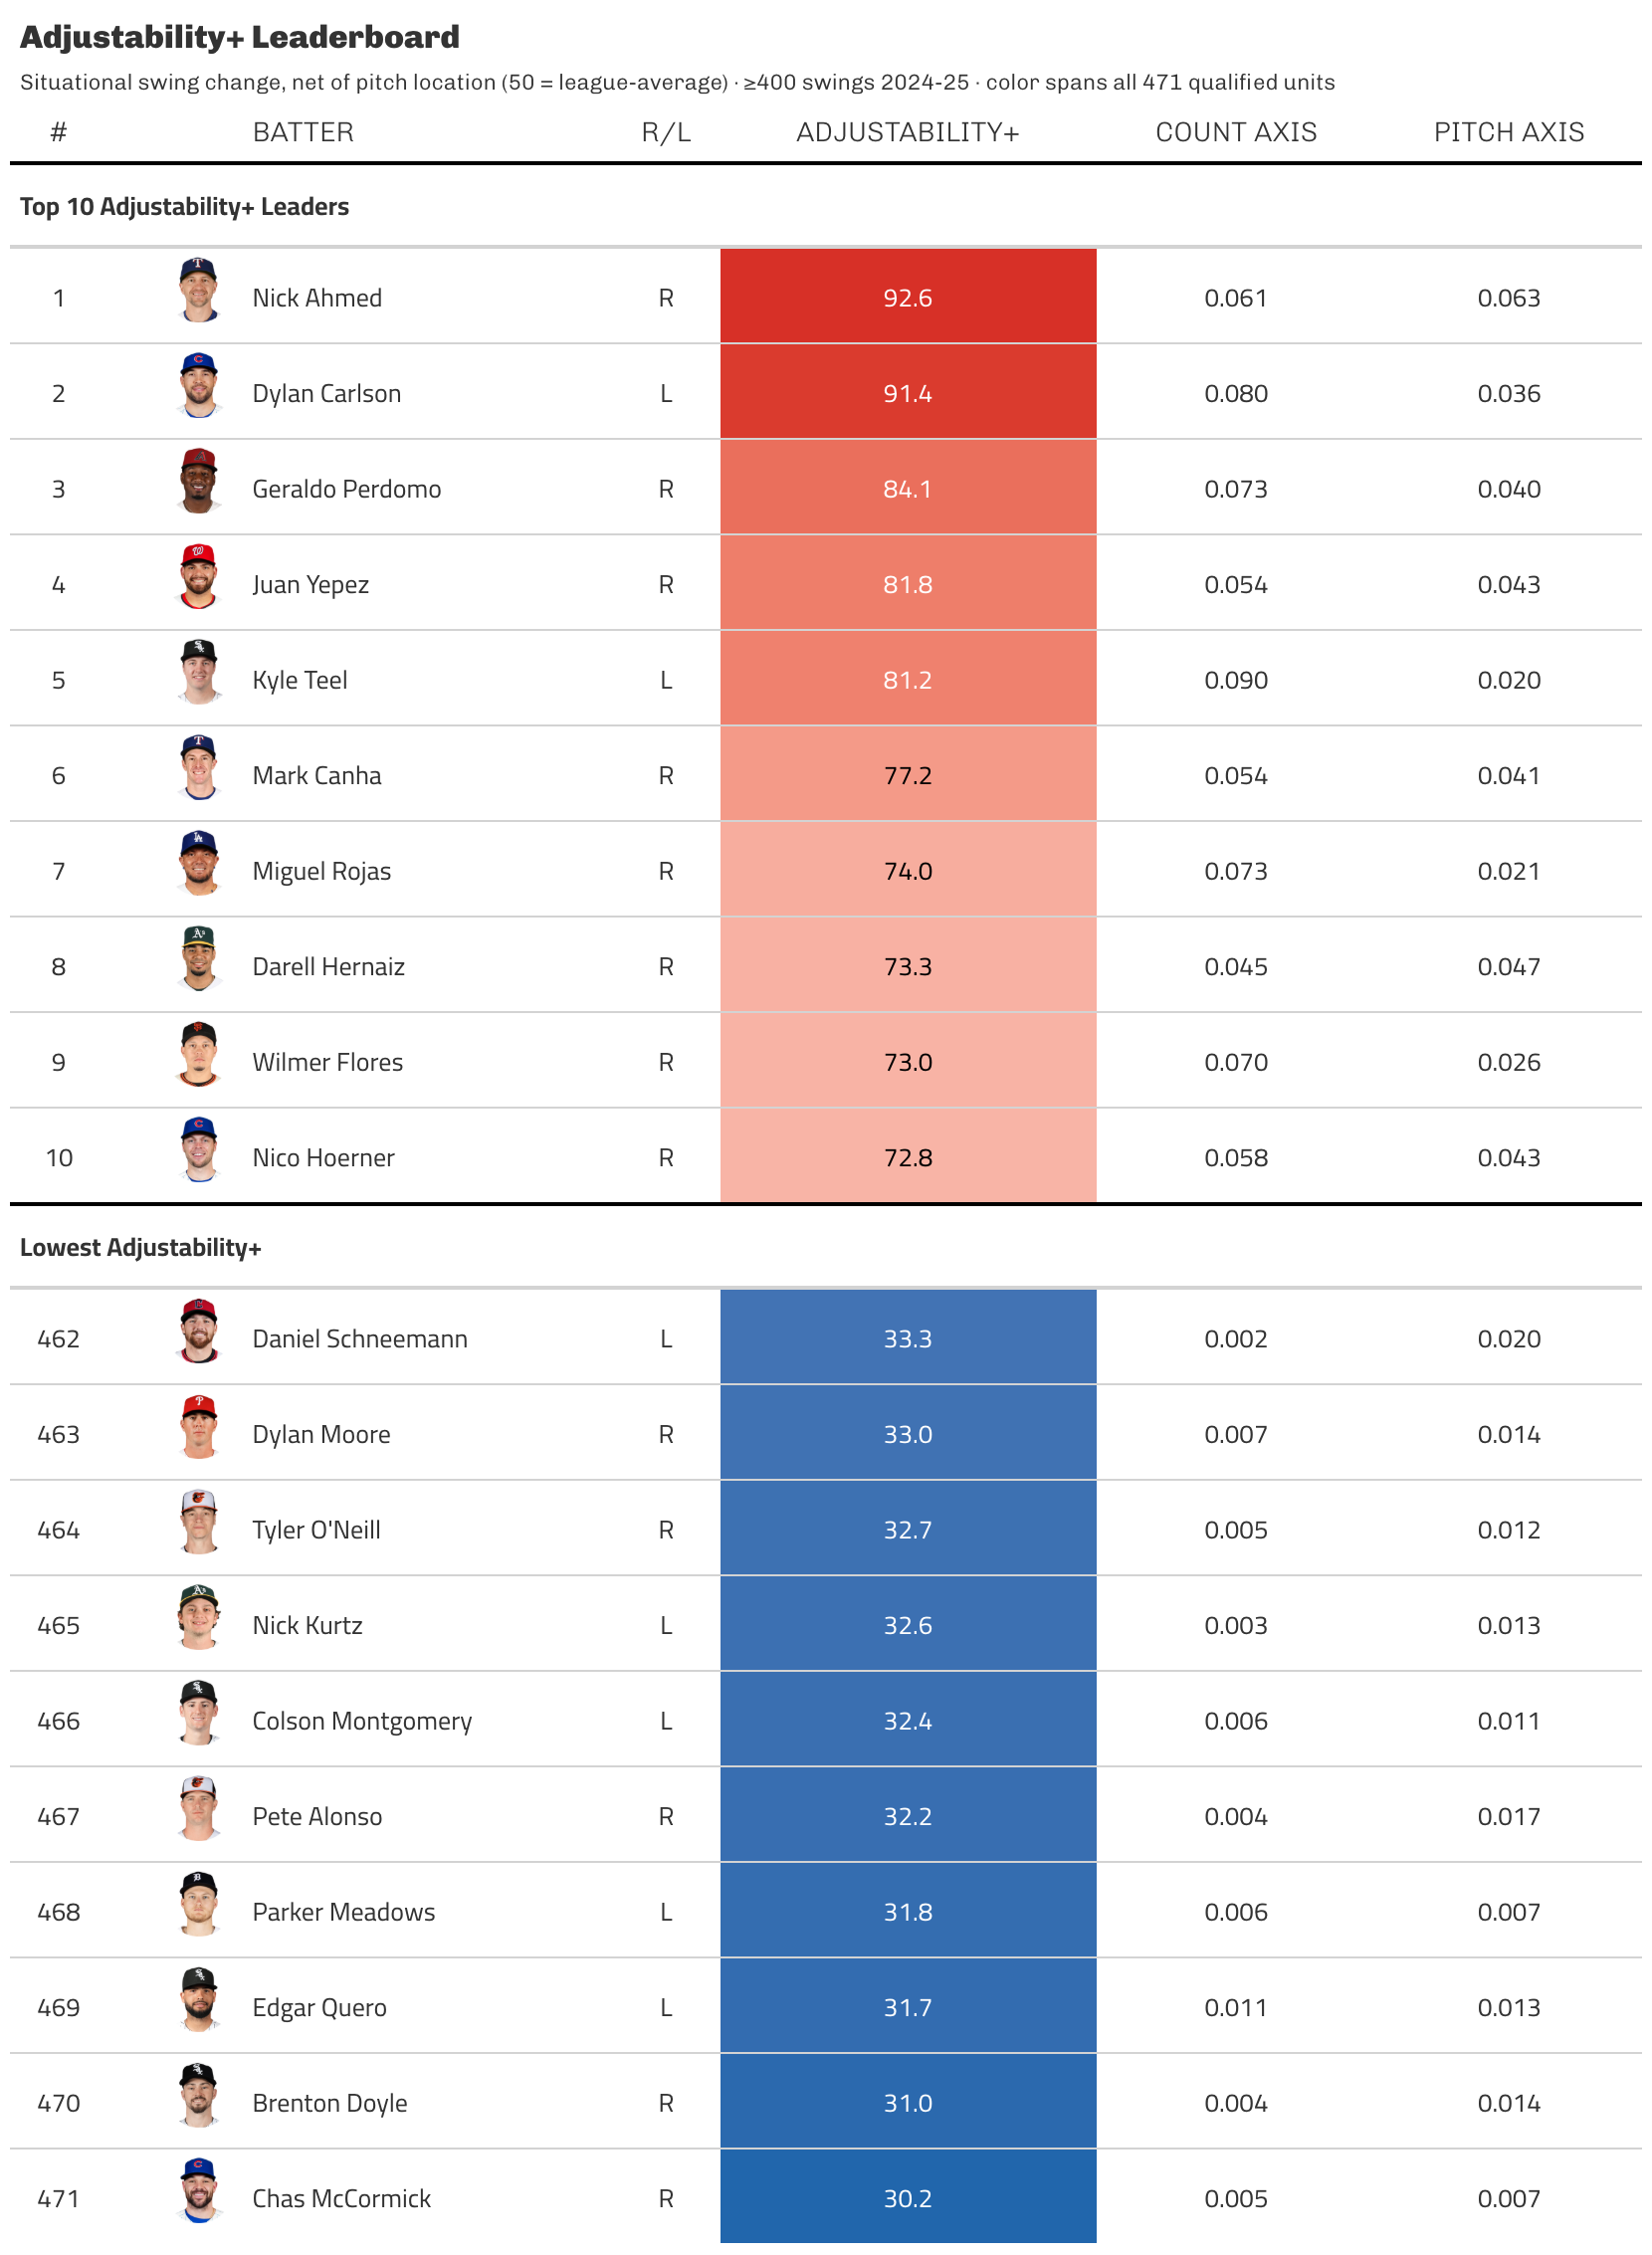

In [3]:
REGEN <- FALSE
if (REGEN) {
  system2("/usr/local/bin/Rscript", args = "src/uncommited/leaderboard_table.R", wait = TRUE)
}
for (png in c("adjustability_leaderboard_gt.png", "adjustability_bottom_gt.png")) {
  p <- plot_path(png)
  if (file.exists(p)) IRdisplay::display_png(file = p)
  else cat(sprintf("Not found: %s — set REGEN <- TRUE and re-run.\n", png))
}

# Adjusting Value

In [4]:
cat(sprintf("%d units loaded\n", nrow(cf)))
axes <- c("runs_total","runs_count","runs_gamestate","runs_platoon",
          "runs_interaction","runs_total_2k","runs_per_swing")
print(round(sapply(cf[axes], function(x)
  c(mean=mean(x,na.rm=T), `50%`=median(x,na.rm=T), sd=sd(x,na.rm=T),
    min=min(x,na.rm=T), max=max(x,na.rm=T))), 4))

466 units loaded


     runs_total runs_count runs_gamestate runs_platoon runs_interaction
mean     0.1397     0.0260        -0.0021       0.1024           0.0133
50%      0.0334    -0.0409         0.0061       0.0271           0.0185
sd       1.0342     0.9459         0.1844       0.3983           0.2391
min     -2.7955    -3.2082        -0.9570      -1.1953          -0.6067
max      5.0343     5.1765         0.6994       2.3981           1.0109
     runs_total_2k runs_per_swing
mean        0.1215         0.0002
50%         0.0819         0.0001
sd          0.4599         0.0016
min        -1.4192        -0.0036
max         2.1887         0.0074


## Independence of swing quality and adjustability value
### Scatterplots

`geom_smooth()` using formula = 'y ~ x'


`geom_smooth()` using formula = 'y ~ x'


r(swing_plus) = -0.213  (n = 466)
r(runs_total) = +0.379  (n = 466)
r(runs_total_2k) = -0.046  (n = 466)


`geom_smooth()` using formula = 'y ~ x'


`geom_smooth()` using formula = 'y ~ x'


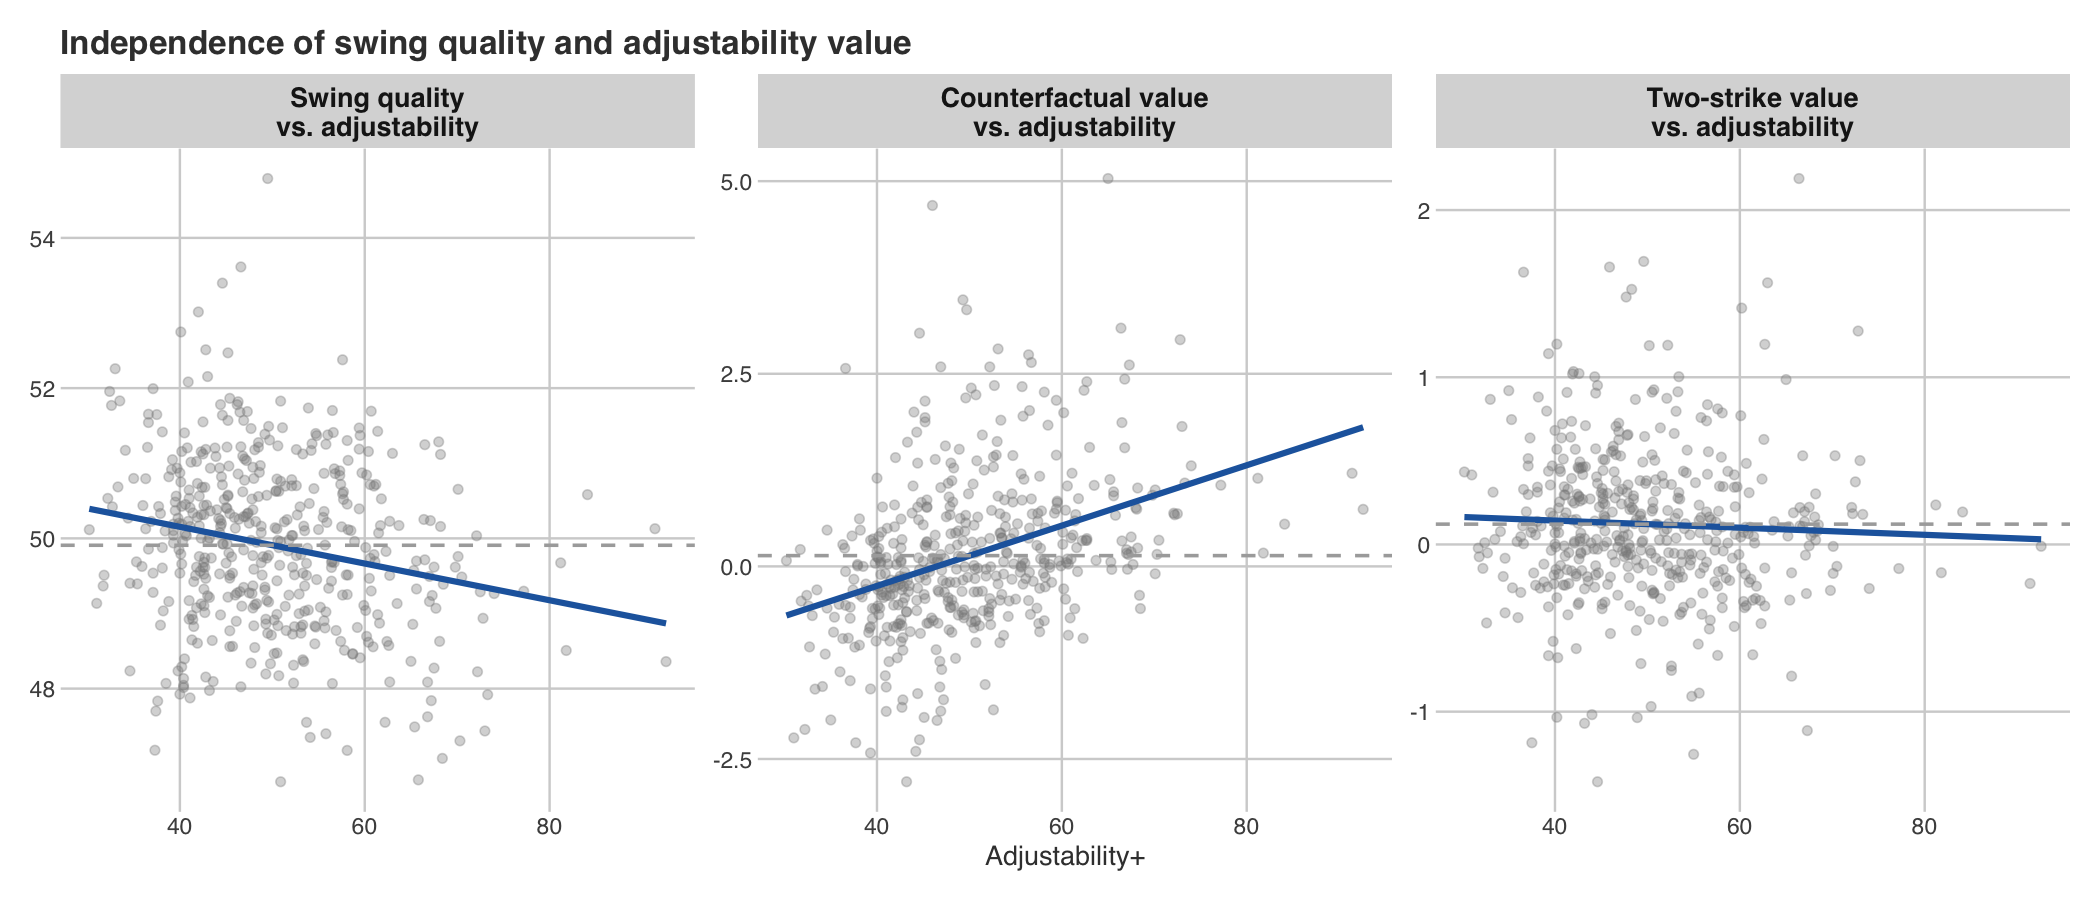

r(k, adj+) = -0.076  (n = 466)


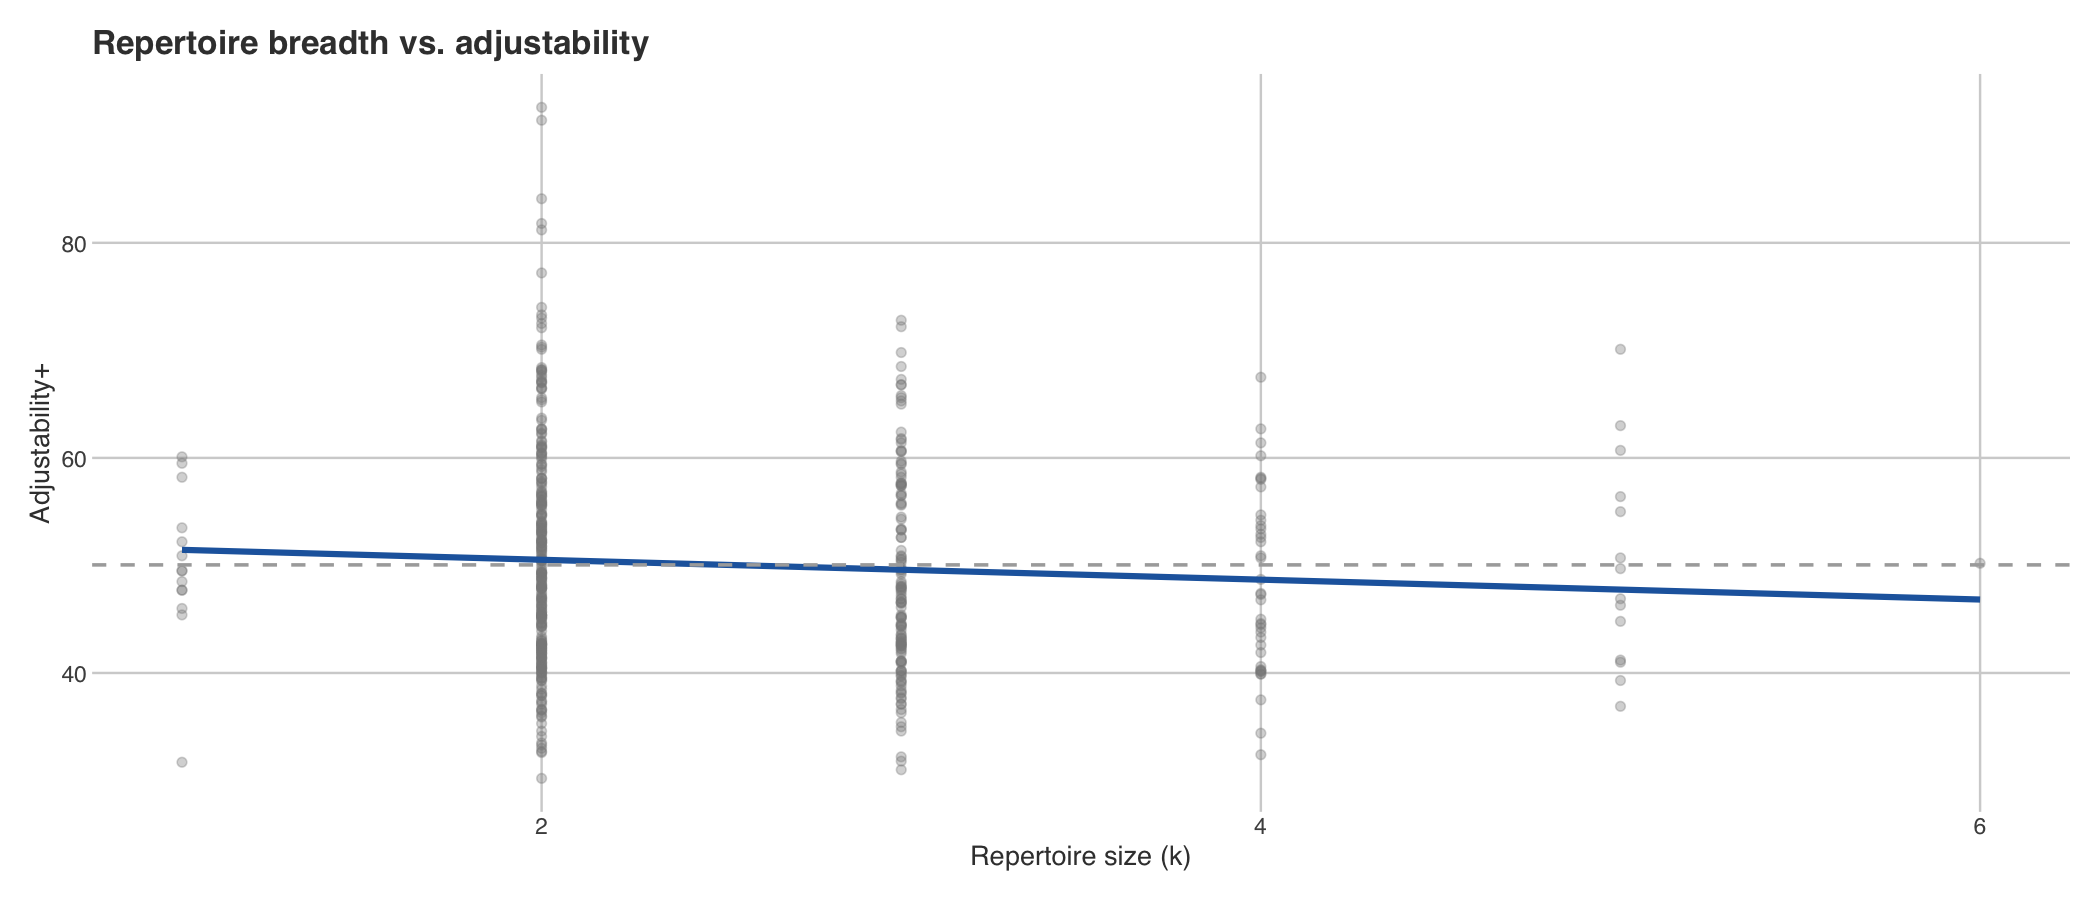

In [5]:
rep_data <- read_parquet(file.path(DATA, "repertoire_scores.parquet"),
                         col_select = c("batter_id","batter_stand","k","effective_shapes"))

cf_full <- cf |>
  left_join(rep_data, by = c("batter_id","batter_stand"))

# ── Faceted plot: first three panels ──────────────────────────────────────────
panel_specs <- list(
  list(y = "swing_plus",    label = "Swing quality\nvs. adjustability"),
  list(y = "runs_total",    label = "Counterfactual value\nvs. adjustability"),
  list(y = "runs_total_2k", label = "Two-strike value\nvs. adjustability")
)

long_df <- map_dfr(panel_specs, function(p) {
  cf_full |>
    select(x = adjustability_plus, y = !!sym(p$y)) |>
    drop_na() |>
    mutate(panel = p$label)
}) |>
  mutate(panel = factor(panel, levels = map_chr(panel_specs, "label")))

annot_df <- long_df |>
  group_by(panel) |>
  summarise(
    r      = cor(x, y),
    mean_y = mean(y),
    ann_x  = min(x) + diff(range(x)) * 0.04,
    ann_y  = max(y) - diff(range(y)) * 0.06,
    .groups = "drop"
  )

plt_facet <- ggplot(long_df, aes(x, y)) +
  geom_point(alpha = 0.35, size = 1.8, color = "#888888") +
  geom_smooth(method = "lm", se = FALSE, color = "#2166ac", linewidth = 1.4) +
  geom_hline(data = annot_df, aes(yintercept = mean_y),
             color = "#aaaaaa", linewidth = 0.8, linetype = "dashed") +
  facet_wrap(~ panel, scales = "free", nrow = 1) +
  labs(title = "Independence of swing quality and adjustability value",
       x = "Adjustability+", y = NULL) +
  FT_THEME +
  theme(strip.text   = element_text(size = 13, face = "bold"),
        axis.title.x = element_text(size = 13),
        axis.text    = element_text(size = 11))

out_facet <- plot_path("adjustability_independence_facet.png")
ggsave(out_facet, plt_facet, width = 14, height = 5, dpi = 300)
print(plt_facet)
for (p in panel_specs) {
  d <- cf_full |> select(x = adjustability_plus, y = !!sym(p$y)) |> drop_na()
  cat(sprintf("r(%s) = %+.3f  (n = %d)\n", p$y, cor(d$x, d$y), nrow(d)))
}

# ── Standalone: repertoire breadth vs adjustability ───────────────────────────
d4 <- cf_full |> select(x = k, y = adjustability_plus) |> drop_na()
r4 <- cor(d4$x, d4$y)

plt4 <- ggplot(d4, aes(x, y)) +
  geom_point(alpha = 0.35, size = 1.8, color = "#888888") +
  geom_smooth(method = "lm", se = FALSE, color = "#2166ac", linewidth = 1.4) +
  geom_hline(yintercept = mean(d4$y), color = "#aaaaaa", linewidth = 0.8, linetype = "dashed") +
  
  labs(title = "Repertoire breadth vs. adjustability",
       x = "Repertoire size (k)", y = "Adjustability+") +
  FT_THEME +
  theme(axis.title = element_text(size = 13),
        axis.text  = element_text(size = 11))

ggsave(plot_path("adjustability_repertoire_k_vs_adjplus.png"), plt4,
       width = 6, height = 4.5, dpi = 300)
print(plt4)
cat(sprintf("r(k, adj+) = %+.3f  (n = %d)\n", r4, nrow(d4)))

## Adjustability value leaderboards

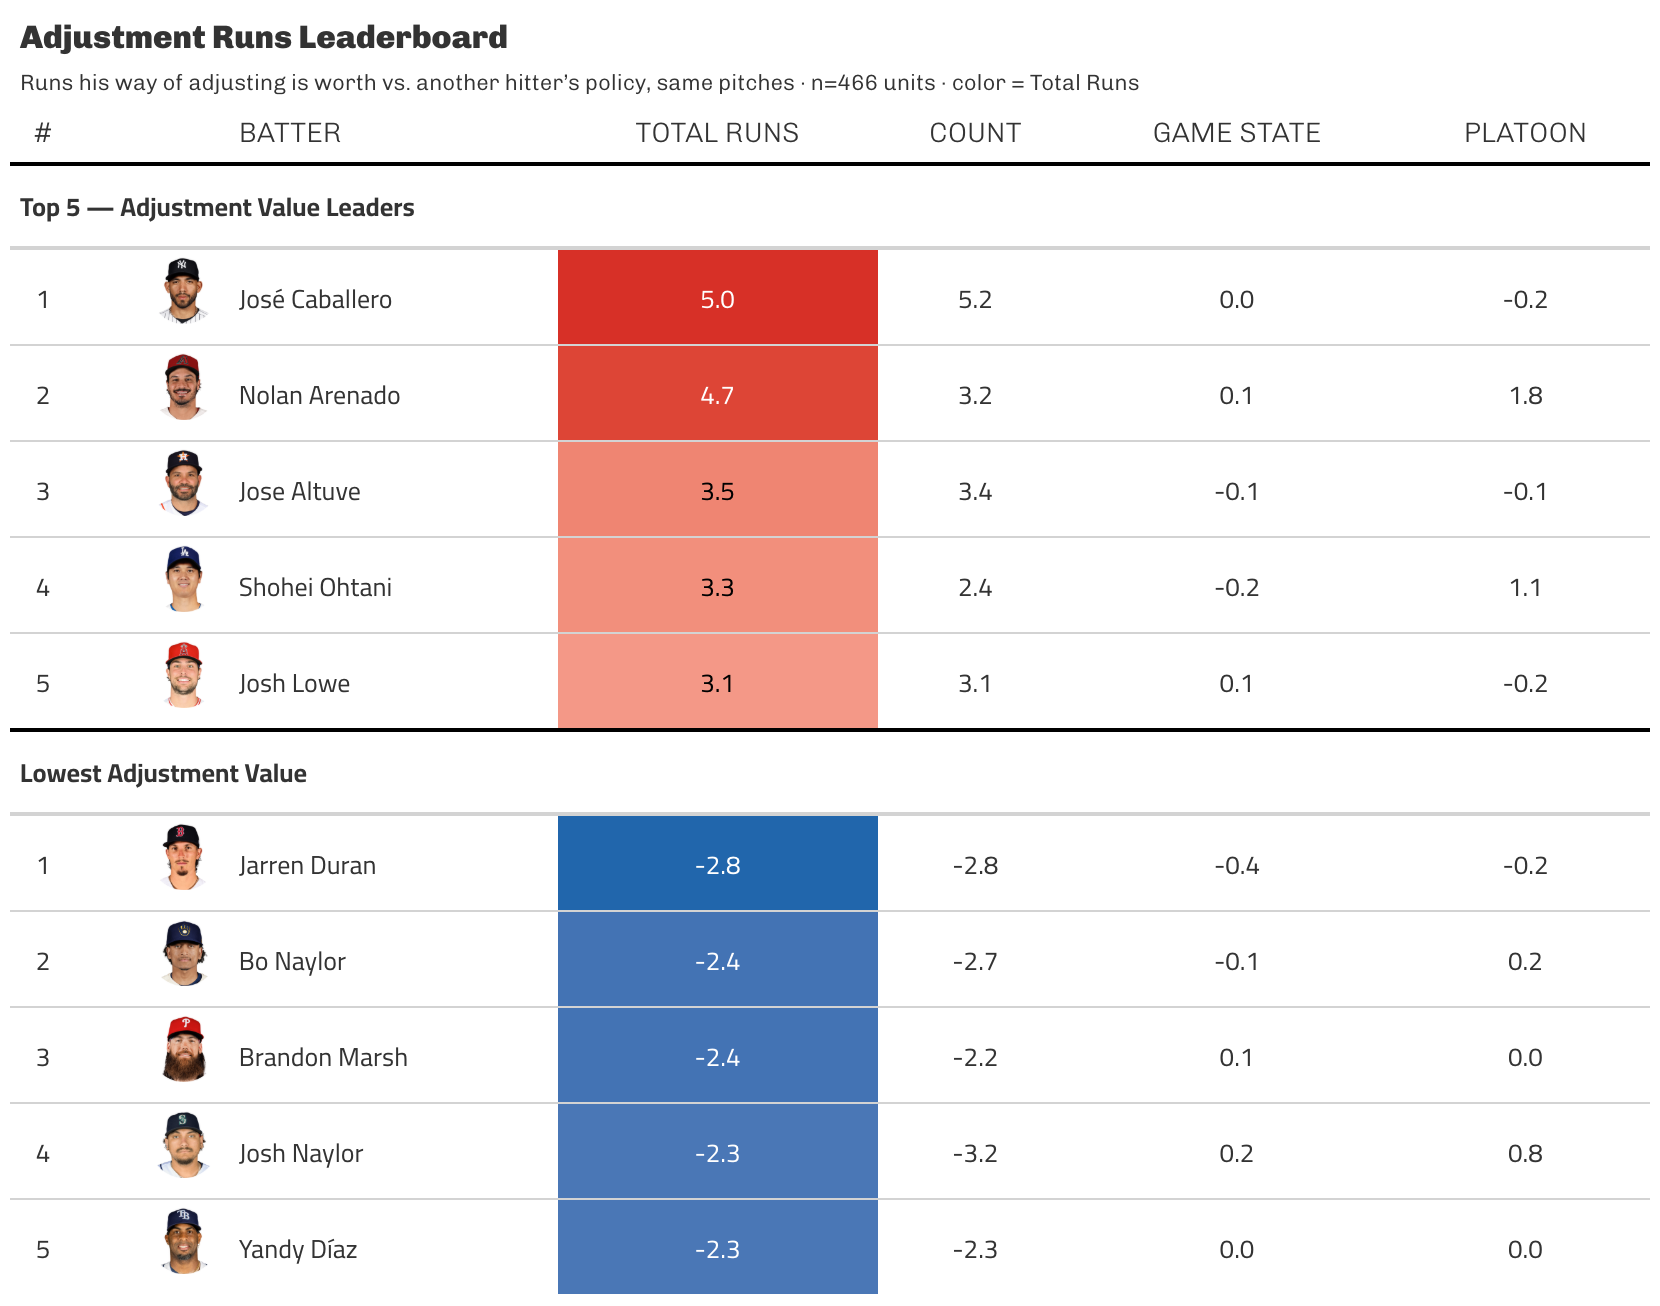

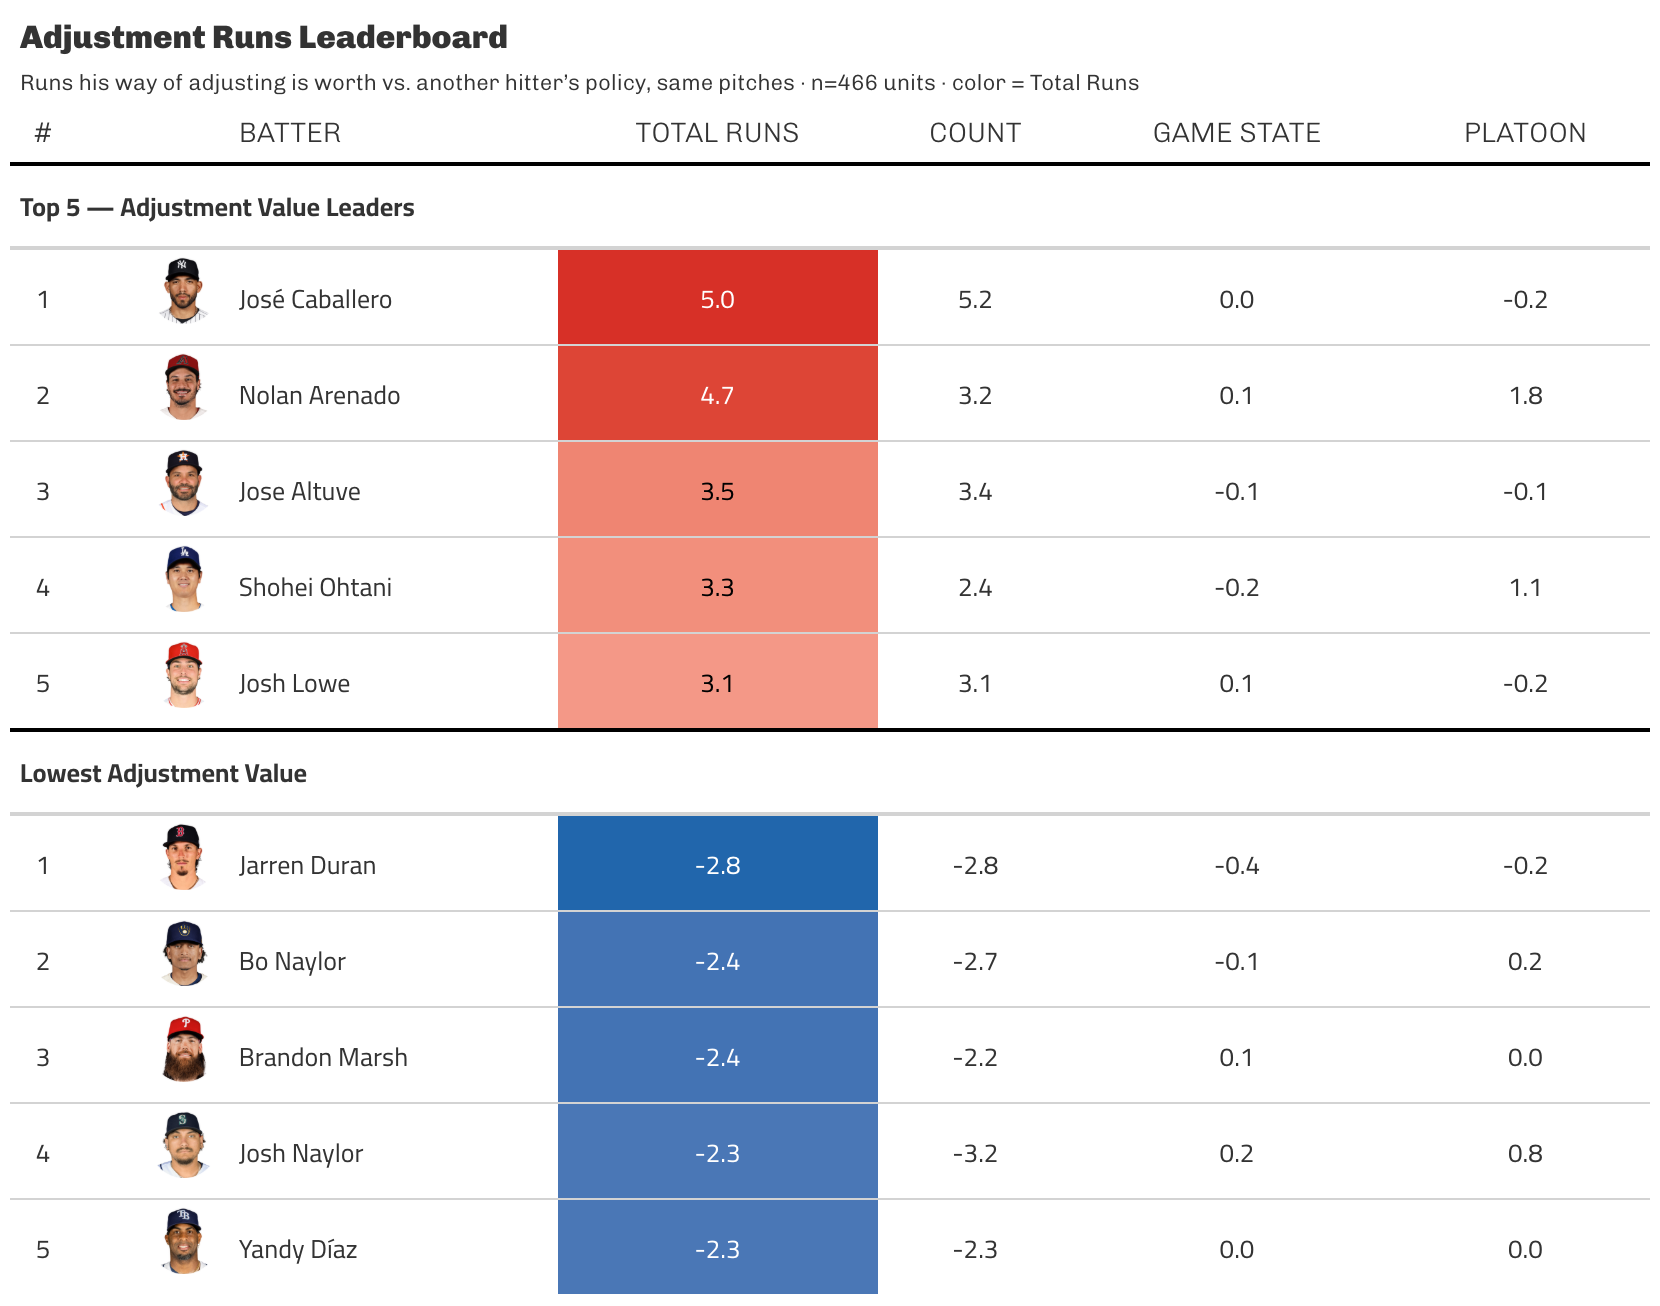

In [6]:
for (png in c("adjustability_value_top_gt.png", "adjustability_value_bottom_gt.png")) {
  p <- plot_path(png)
  if (file.exists(p)) IRdisplay::display_png(file = p)
  else cat(sprintf("Not yet generated: %s\n", png))
}

## Distribution of adjustment value

Saved → /Users/theoauyeung/Documents/swing_repertoire/results/plots/adjustability/adjustability_runs_distribution.png


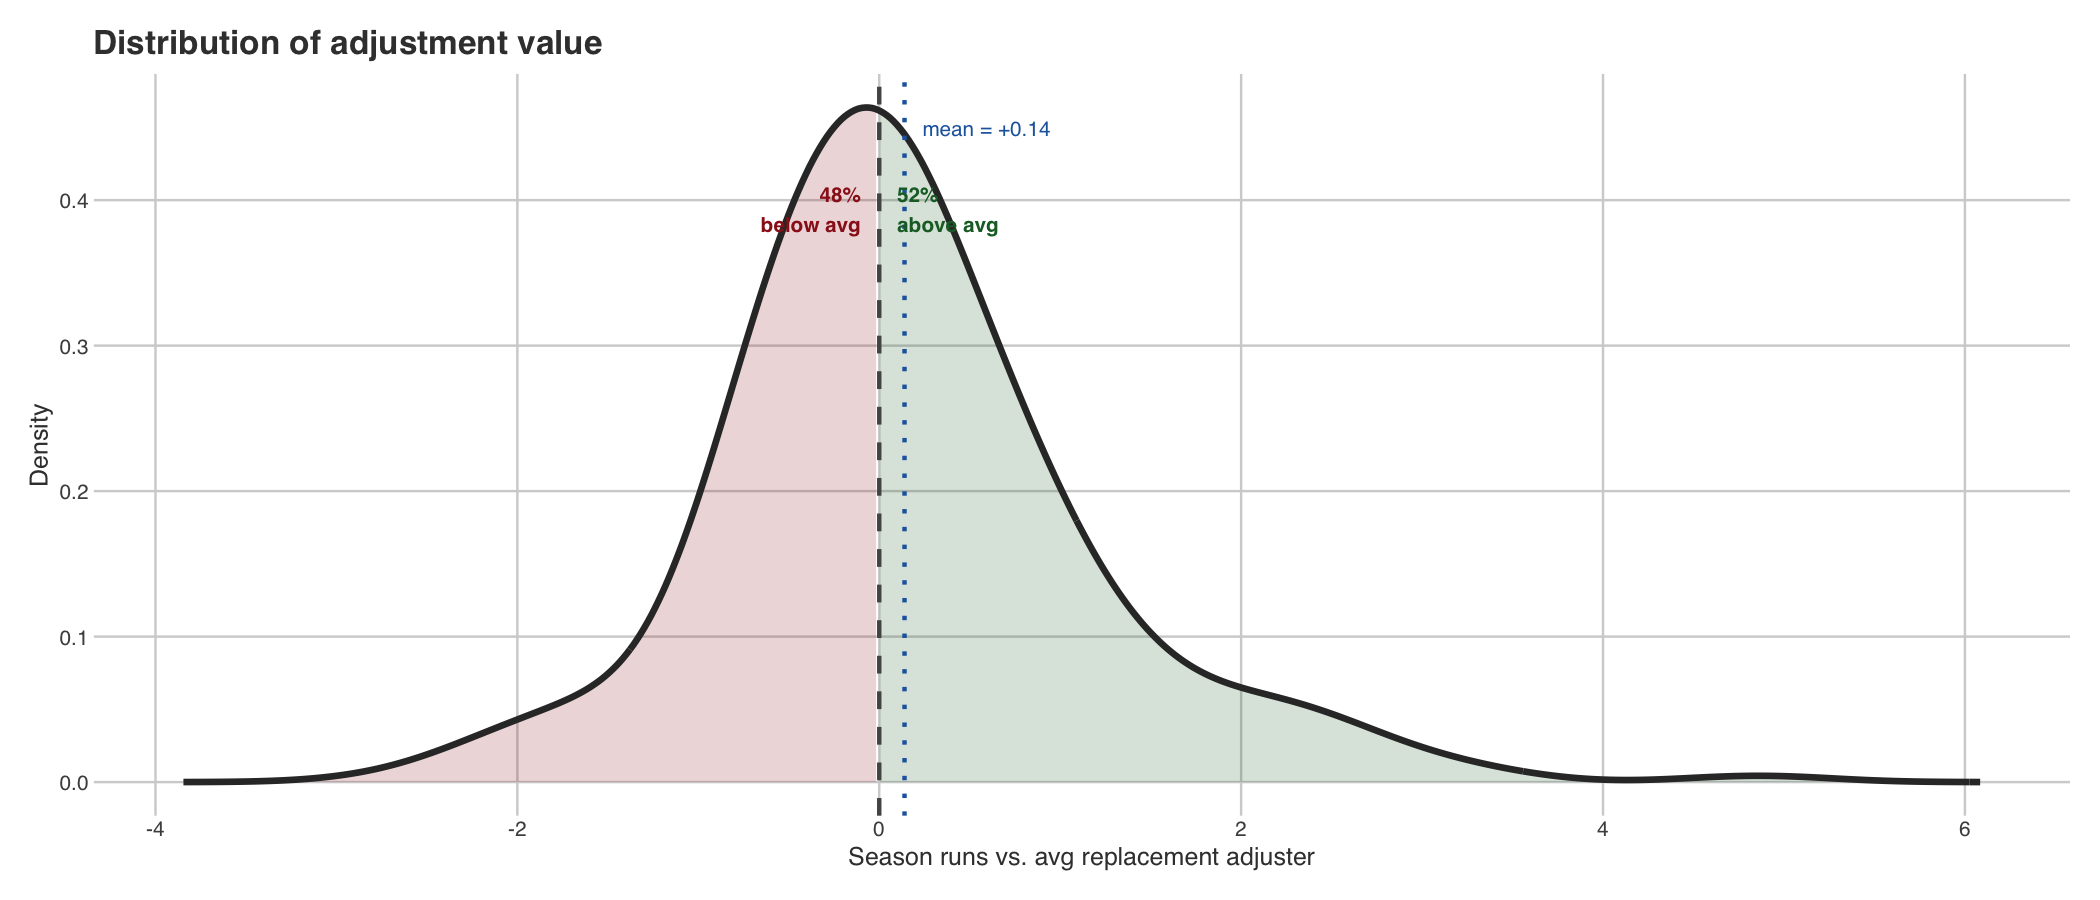

In [7]:
mean_val <- mean(cf$runs_total)
pct_pos  <- mean(cf$runs_total > 0) * 100

dens    <- density(cf$runs_total, bw = 0.35)
dens_df <- tibble(x = dens$x, y = dens$y)

plt <- ggplot(dens_df, aes(x, y)) +
  geom_area(data = filter(dens_df, x < 0),  fill = "#9b1c1c", alpha = 0.18) +
  geom_area(data = filter(dens_df, x >= 0), fill = "#1a6b2e", alpha = 0.18) +
  geom_line(color = "#333333", linewidth = 1.5) +
  geom_vline(xintercept = 0,        color = "#555555", linewidth = 1.0, linetype = "dashed") +
  geom_vline(xintercept = mean_val, color = "#2166ac", linewidth = 1.0, linetype = "dotted") +
  annotate("text", x = mean_val + 0.1, y = max(dens_df$y) * 0.97,
           label = sprintf("mean = %+.2f", mean_val),
           hjust = 0, color = "#2166ac", size = 3.5) +
  annotate("text", x = -0.1, y = max(dens_df$y) * 0.85,
           label = sprintf("%.0f%%\nbelow avg", 100 - pct_pos),
           hjust = 1, color = "#9b1c1c", fontface = "bold", size = 3.5) +
  annotate("text", x = 0.1, y = max(dens_df$y) * 0.85,
           label = sprintf("%.0f%%\nabove avg", pct_pos),
           hjust = 0, color = "#1a6b2e", fontface = "bold", size = 3.5) +
  labs(title = "Distribution of adjustment value",
       x = "Season runs vs. avg replacement adjuster", y = "Density") +
  coord_cartesian(ylim = c(0, NA)) +
  FT_THEME

out <- plot_path("adjustability_runs_distribution.png")
ggsave(out, plt, width = 8, height = 4.5, dpi = 150)
print(plt)
cat(sprintf("Saved → %s\n", out))

## Where Does Adjustment Value Come From

Warning message:
“annotation$theme is not a valid theme.
Please use `theme()` to construct themes.”


Warning message:
“annotation$theme is not a valid theme.
Please use `theme()` to construct themes.”


Saved → /Users/theoauyeung/Documents/swing_repertoire/results/plots/adjustability/adjustability_situation_breakdown.png


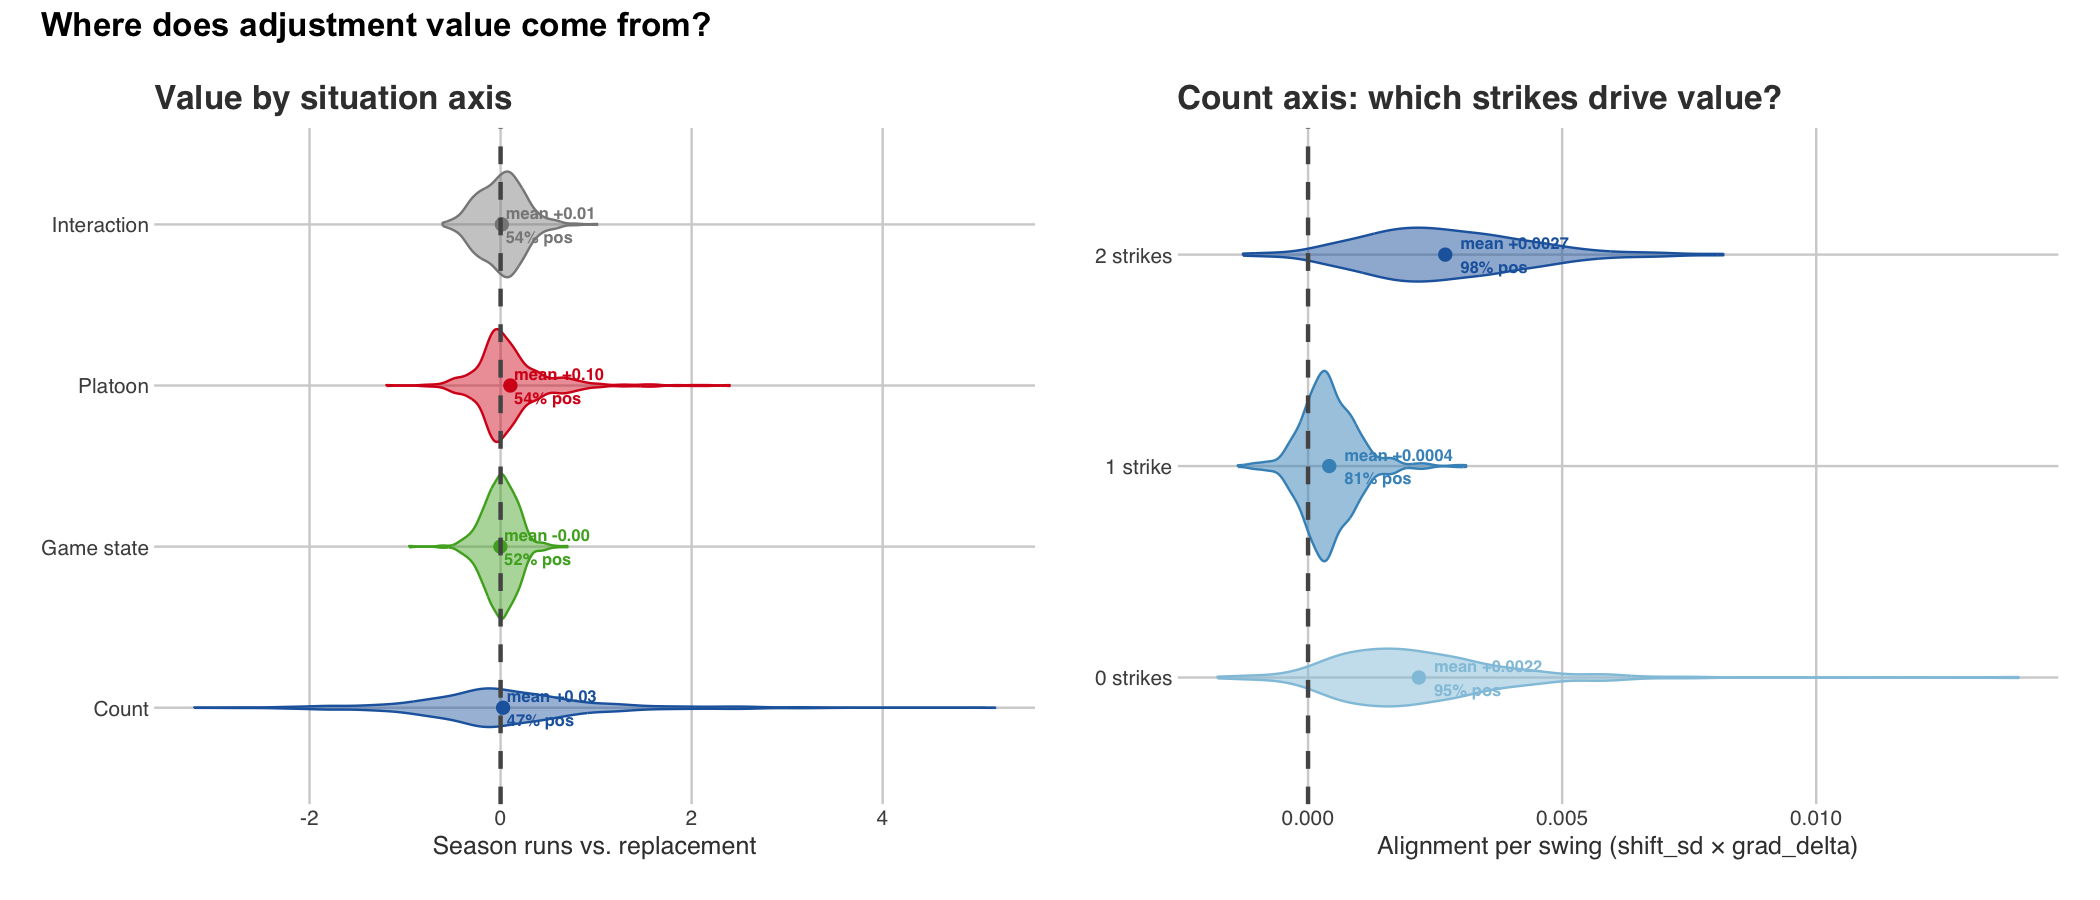

In [8]:
gr <- read_parquet(file.path(DATA, "adjustability_gradients.parquet"))

axes_cols   <- c("runs_count","runs_gamestate","runs_platoon","runs_interaction")
axis_labels <- c("Count","Game state","Platoon","Interaction")
axis_colors <- c("#2166ac","#4dac26","#d7191c","#888888")

# Left panel: violin per axis
long_axes <- cf |>
  select(all_of(axes_cols)) |>
  pivot_longer(everything(), names_to = "axis", values_to = "runs") |>
  mutate(axis = factor(axis, levels = axes_cols, labels = axis_labels))

axis_stats <- long_axes |>
  group_by(axis) |>
  summarise(mn = mean(runs, na.rm = TRUE), pct_pos = mean(runs > 0, na.rm = TRUE) * 100)

p_left <- ggplot(long_axes, aes(x = runs, y = axis, fill = axis, color = axis)) +
  geom_violin(alpha = 0.45, trim = TRUE, show.legend = FALSE) +
  geom_point(data = axis_stats, aes(x = mn, y = axis), size = 2.5, show.legend = FALSE) +
  geom_text(data = axis_stats,
            aes(x = mn + 0.04, y = axis,
                label = sprintf("mean %+.2f\n%.0f%% pos", mn, pct_pos)),
            hjust = 0, size = 2.8, fontface = "bold", show.legend = FALSE) +
  geom_vline(xintercept = 0, color = "#555", linewidth = 1.0, linetype = "dashed") +
  scale_fill_manual(values  = setNames(axis_colors, axis_labels)) +
  scale_color_manual(values = setNames(axis_colors, axis_labels)) +
  labs(title = "Value by situation axis", x = "Season runs vs. replacement", y = NULL) +
  FT_THEME

# Right panel: within count axis by strike count
gr_count <- gr |>
  filter(axis == "count") |>
  mutate(align_per_swing = shift_sd * grad_delta_runs_per_sd)

cell_align <- gr_count |>
  group_by(batter_id, batter_stand, cell) |>
  summarise(align = sum(align_per_swing), .groups = "drop") |>
  filter(cell %in% c("0 strikes","1 strike","2 strikes")) |>
  mutate(cell = factor(cell, levels = c("0 strikes","1 strike","2 strikes")))

cell_colors <- c("0 strikes" = "#92c5de", "1 strike" = "#4393c3", "2 strikes" = "#2166ac")
cell_stats  <- cell_align |>
  group_by(cell) |>
  summarise(mn = mean(align), pct_pos = mean(align > 0) * 100)

p_right <- ggplot(cell_align, aes(x = align, y = cell, fill = cell, color = cell)) +
  geom_violin(alpha = 0.5, trim = TRUE, show.legend = FALSE) +
  geom_point(data = cell_stats, aes(x = mn, y = cell), size = 2.5, show.legend = FALSE) +
  geom_text(data = cell_stats,
            aes(x = mn + 0.0003, y = cell,
                label = sprintf("mean %+.4f\n%.0f%% pos", mn, pct_pos)),
            hjust = 0, size = 2.8, fontface = "bold", show.legend = FALSE) +
  geom_vline(xintercept = 0, color = "#555", linewidth = 1.0, linetype = "dashed") +
  scale_fill_manual(values  = cell_colors) +
  scale_color_manual(values = cell_colors) +
  labs(title = "Count axis: which strikes drive value?",
       x = "Alignment per swing (shift_sd × grad_delta)", y = NULL) +
  FT_THEME

combined <- p_left + p_right +
  plot_annotation(title = "Where does adjustment value come from?",
                  theme = theme(plot.title = element_text(size = 16, face = "bold")))

out <- plot_path("adjustability_situation_breakdown.png")
ggsave(out, combined, width = 13, height = 5, dpi = 150)
print(combined)
cat(sprintf("Saved → %s\n", out))

## Per-dial attribution (focal hitters)

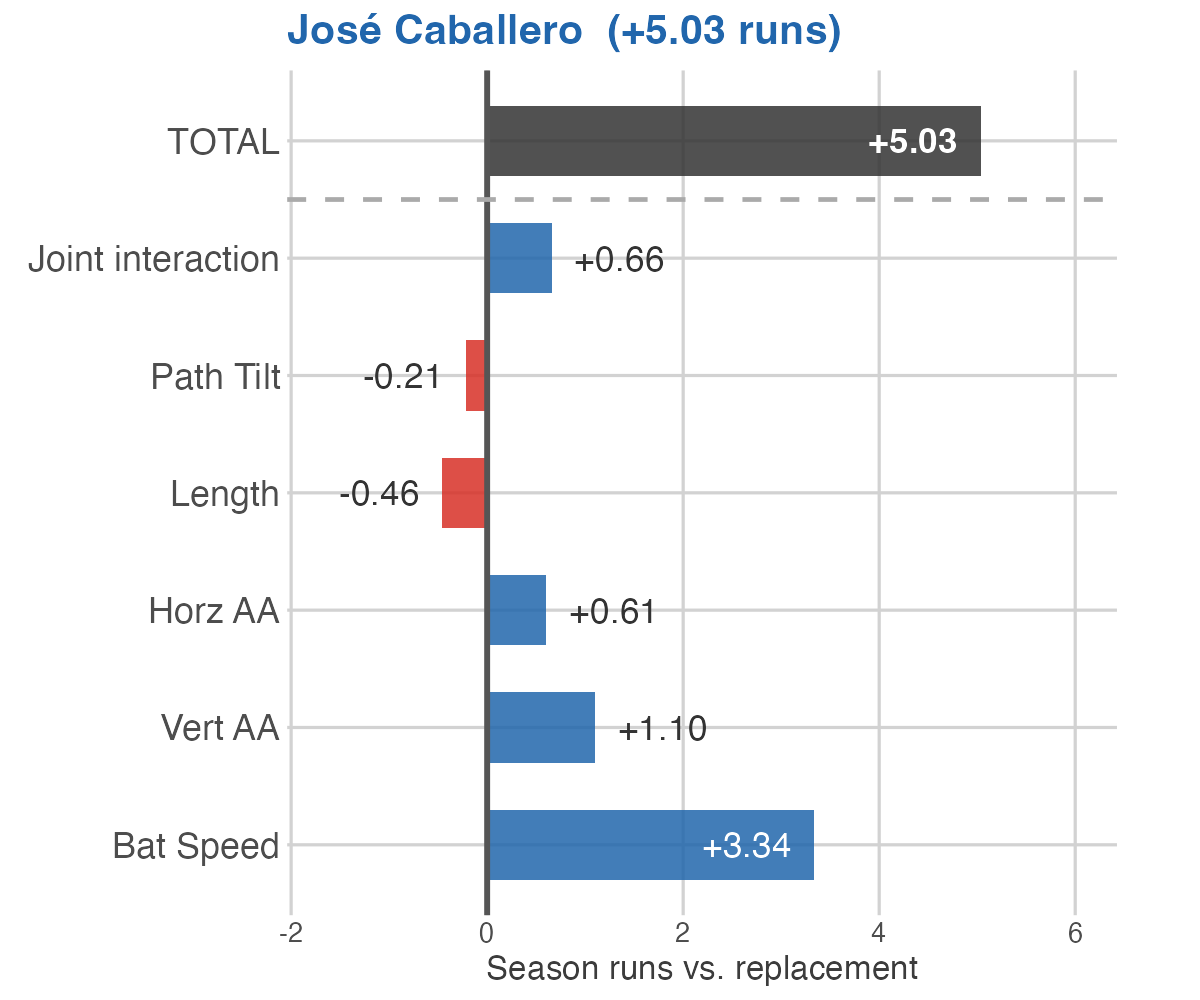

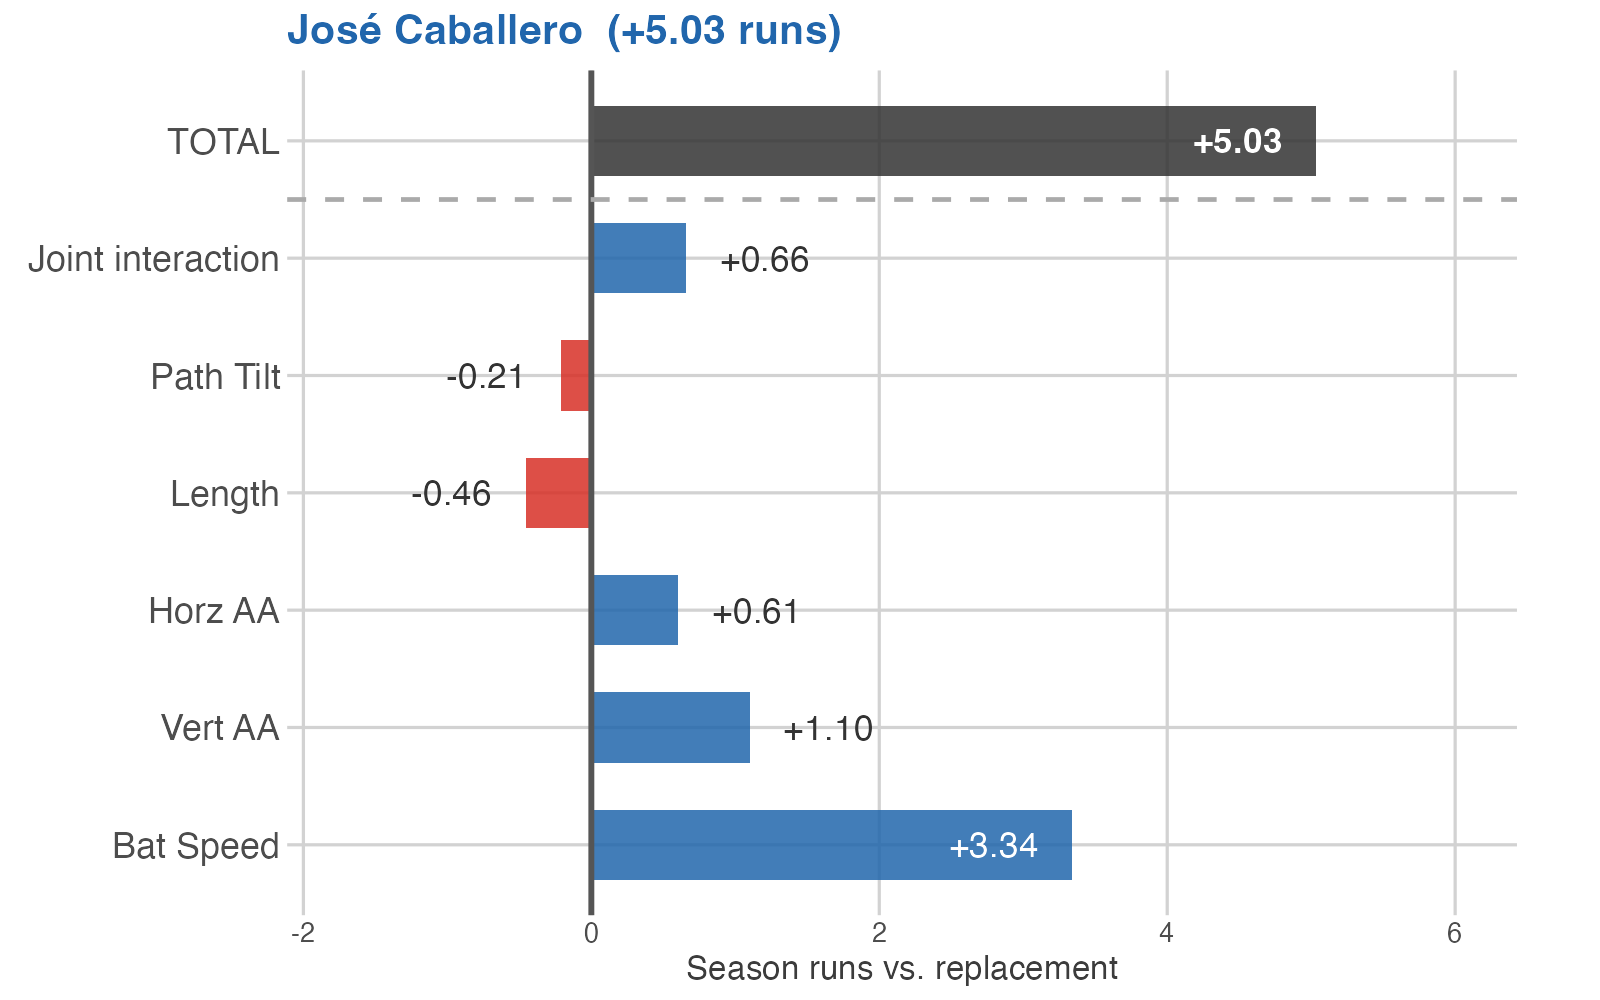

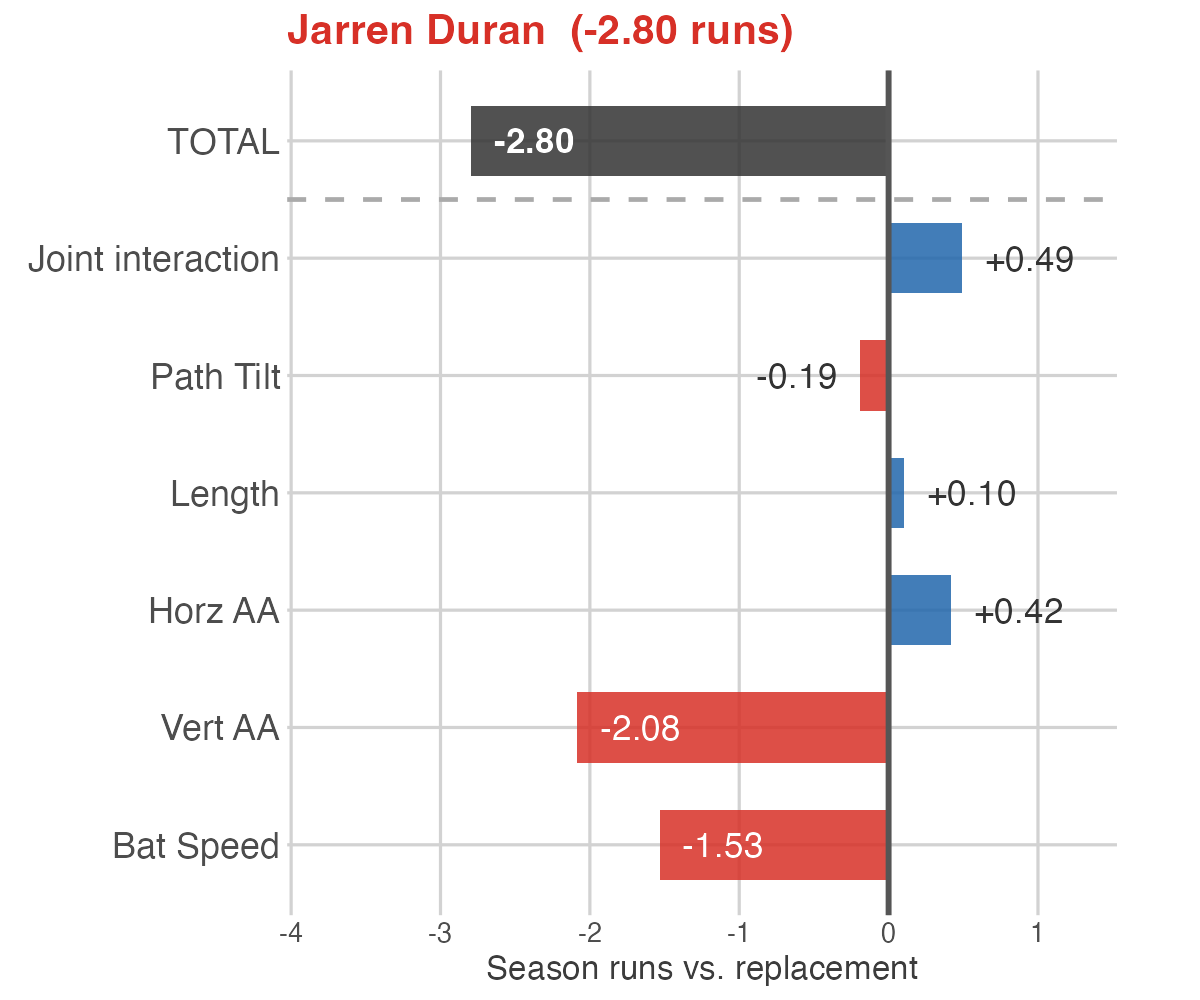

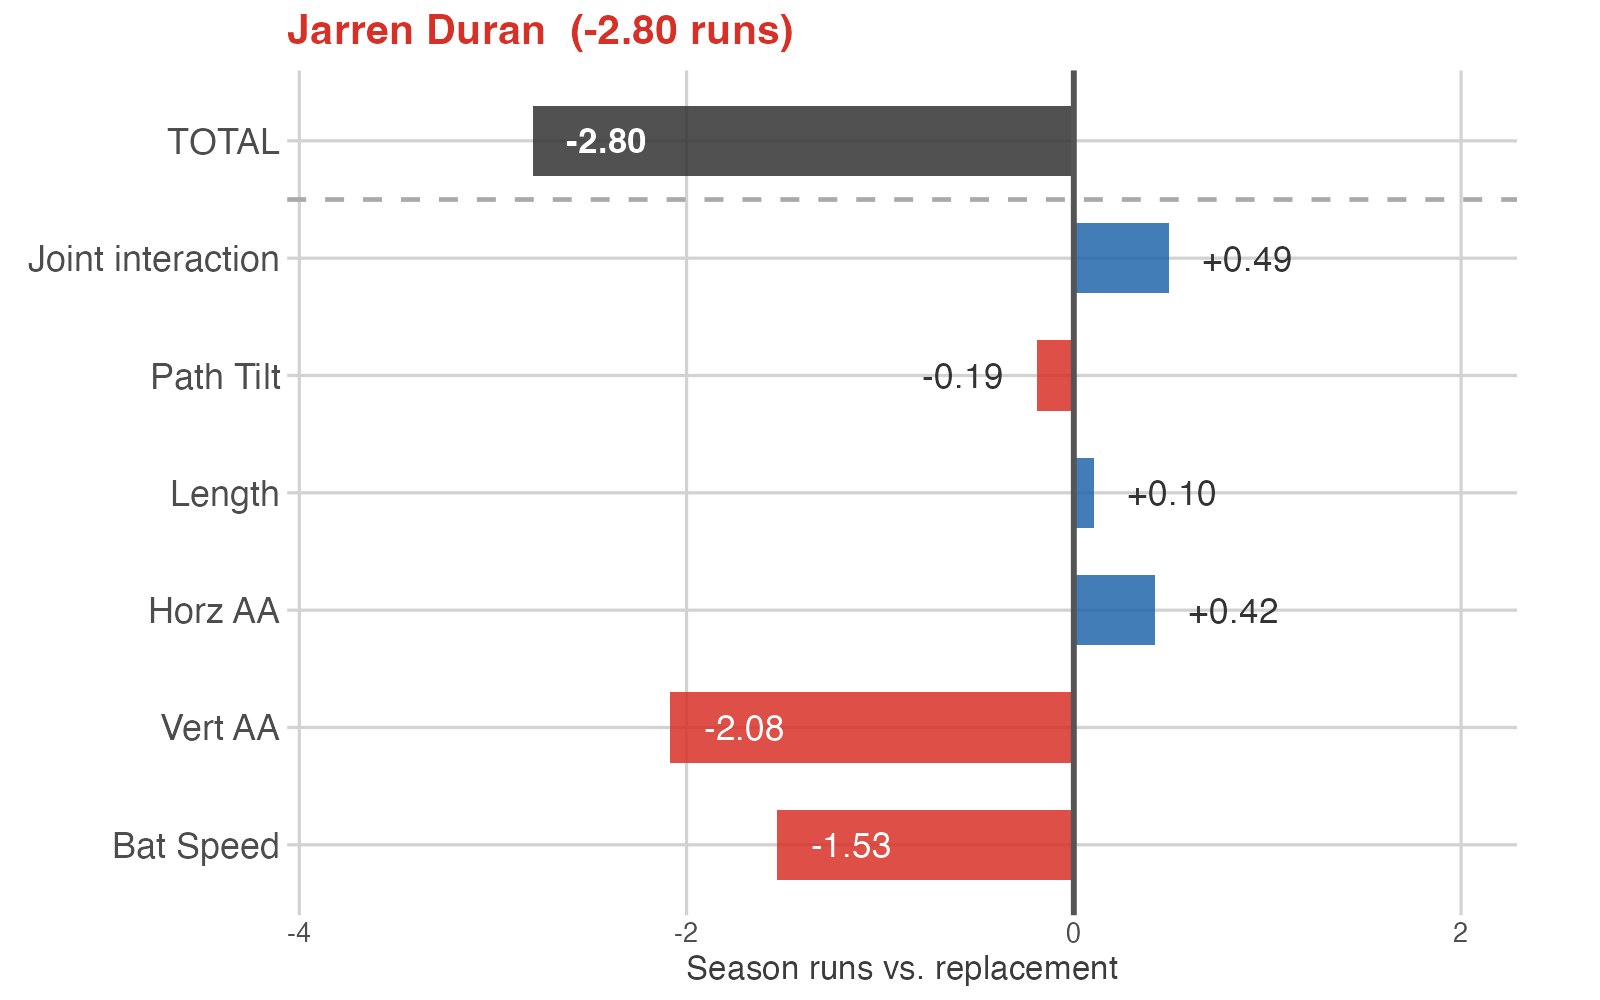

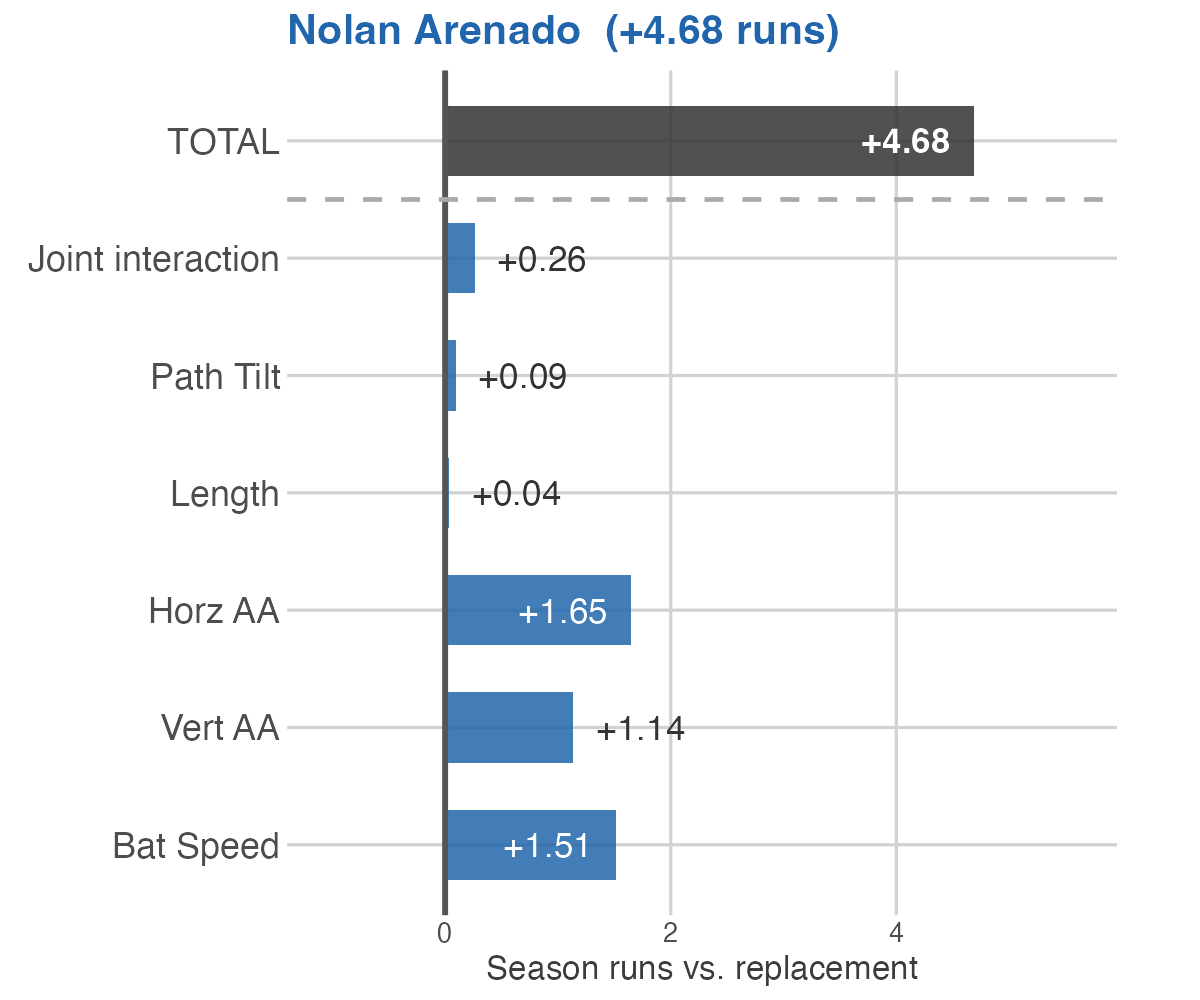

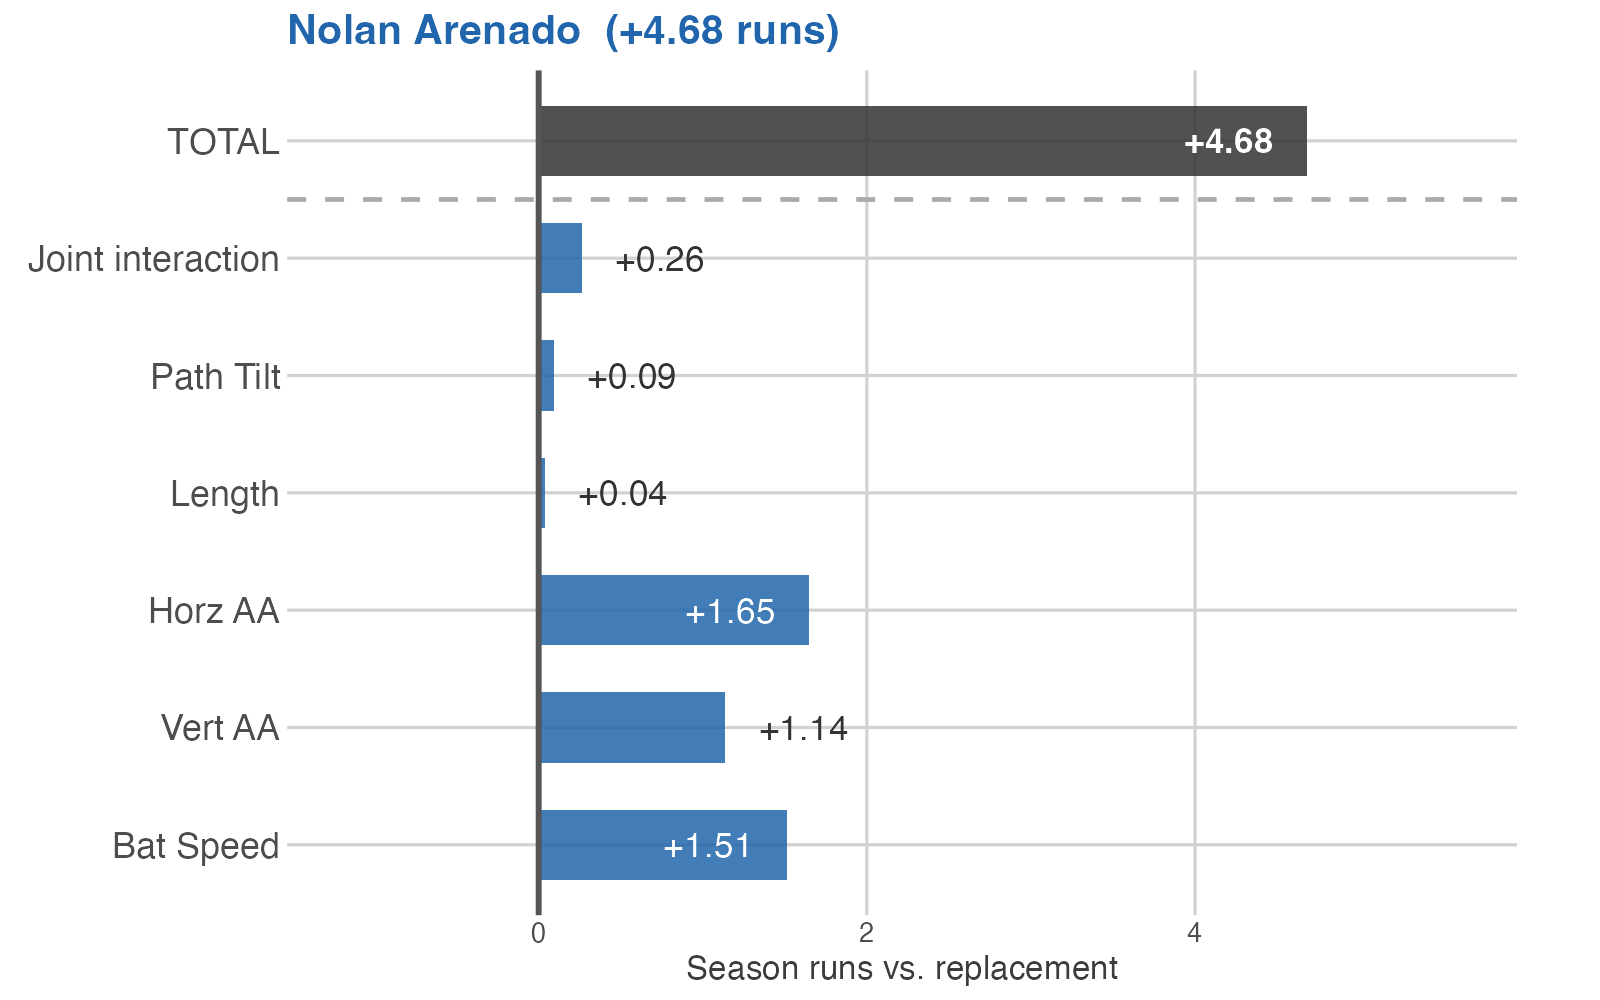

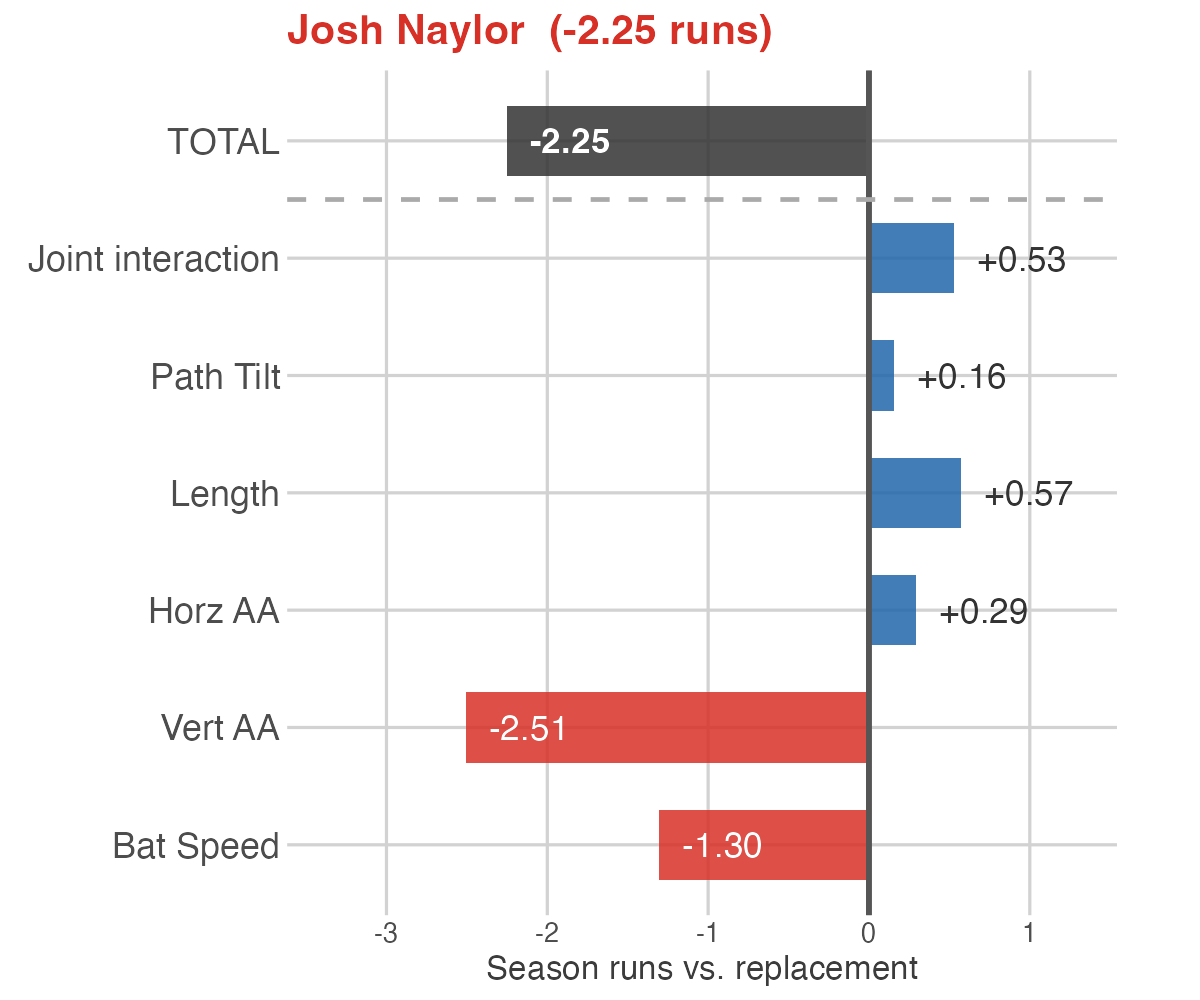

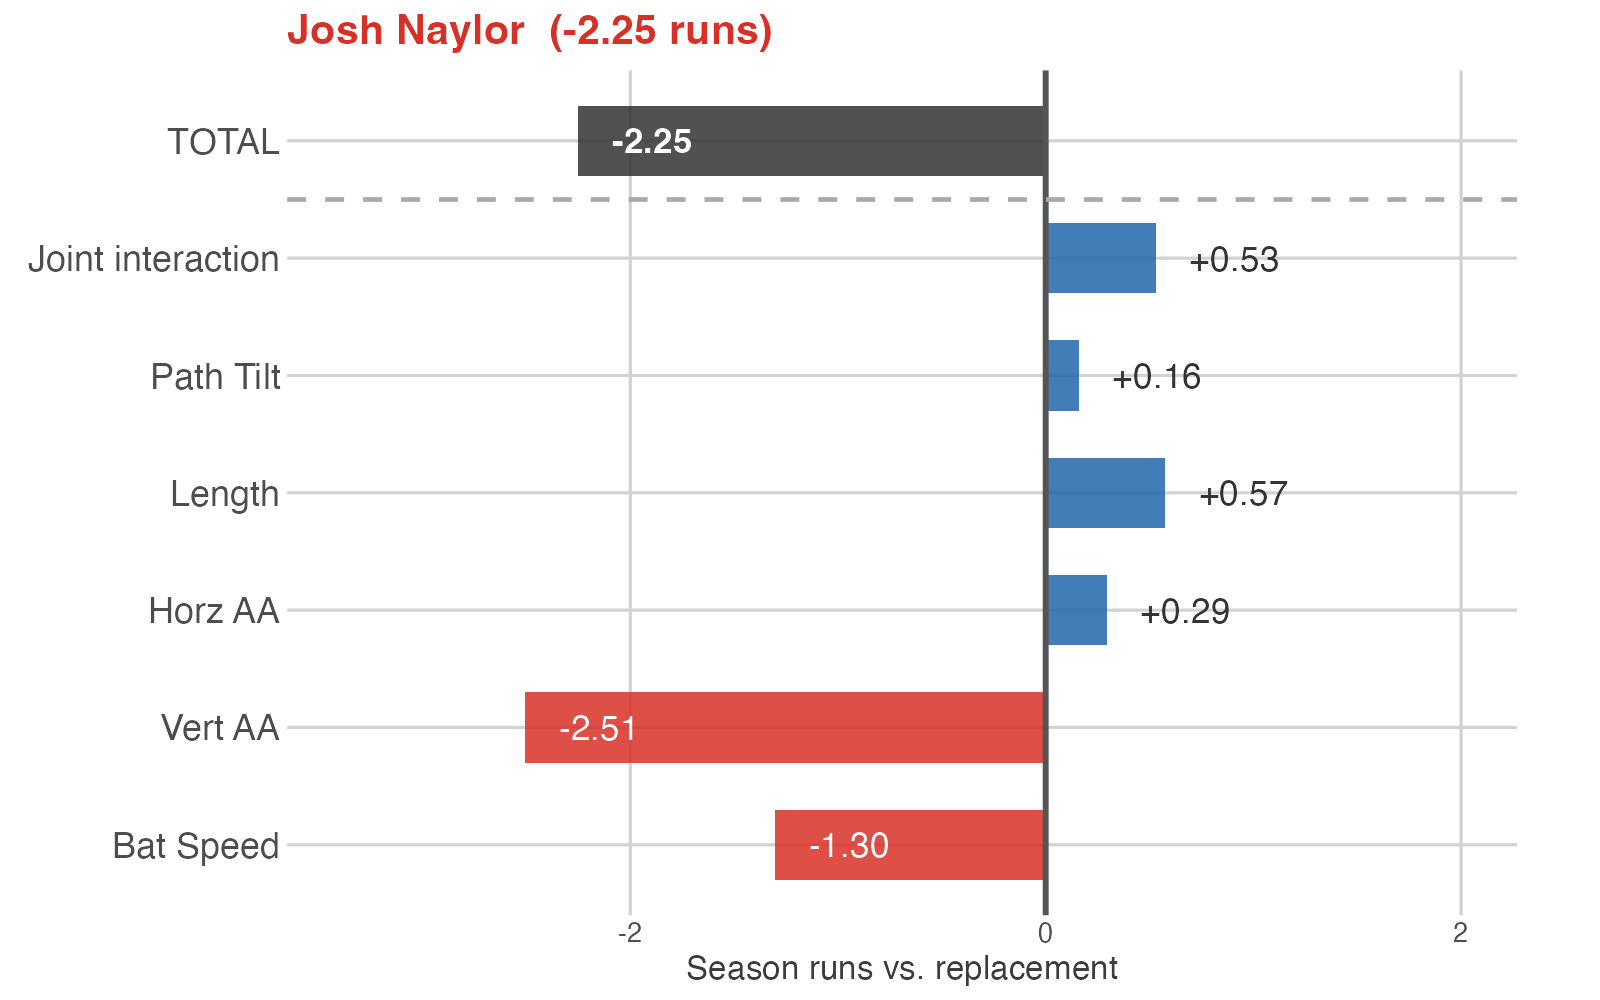

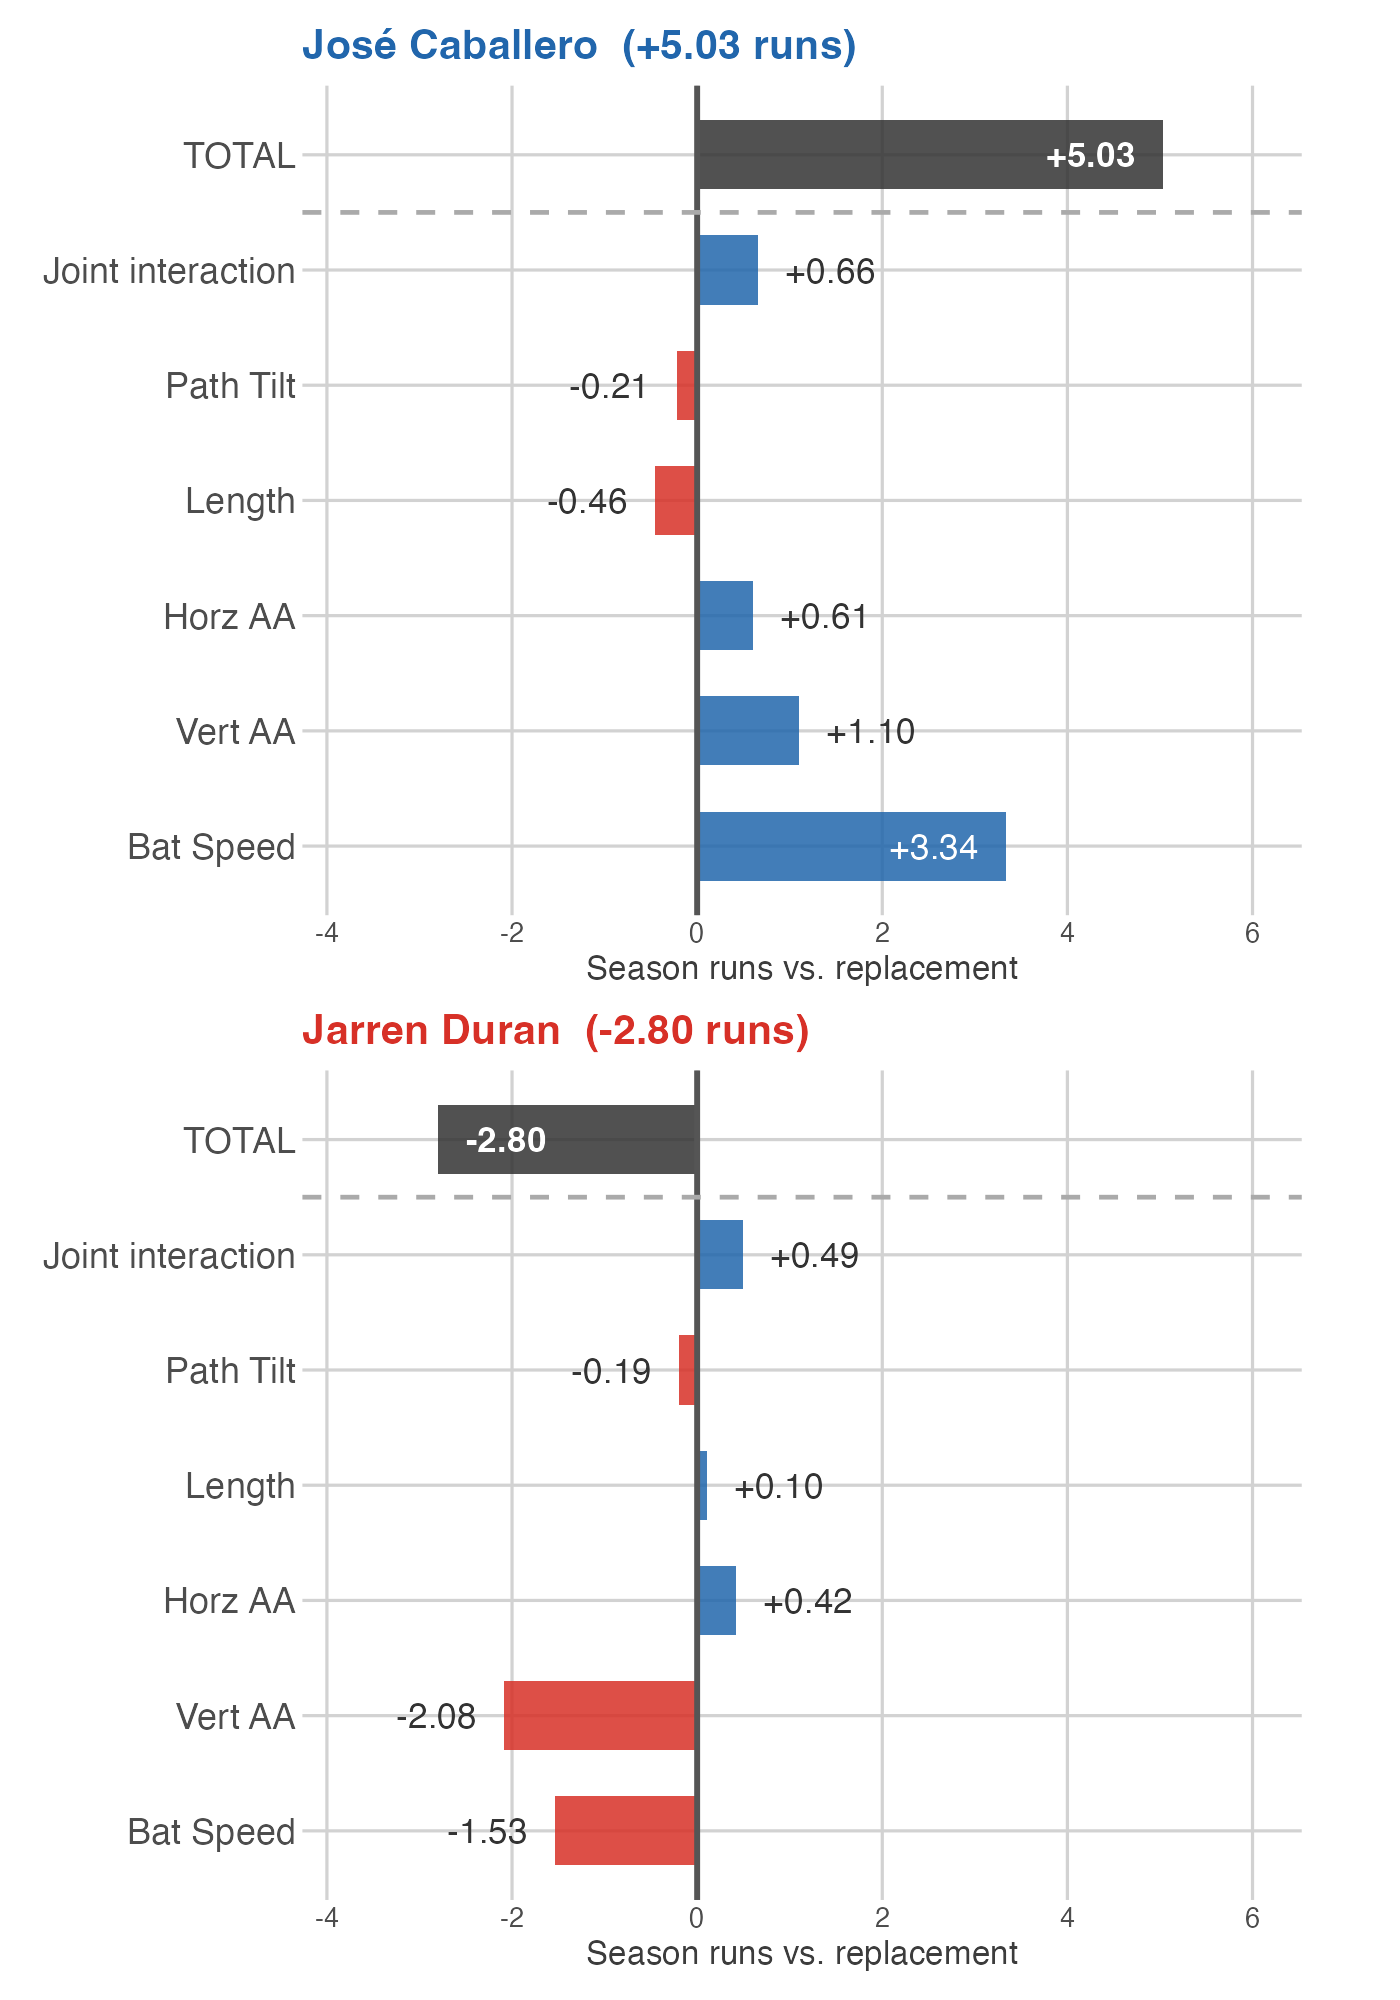

Dial correlations with runs_total:


  Bat Speed                      r = +0.775
  Vert AA                        r = +0.702
  Horz AA                        r = +0.199
  Length                         r = -0.401
  Path Tilt                      r = -0.022
  Joint interaction              r = +0.012


In [9]:
abl <- read_parquet(file.path(DATA, "adjustability_dial_ablation.parquet"))

dial_order  <- c("runs_dial_bat_speed","runs_dial_vert_attack_angle",
                 "runs_dial_horz_attack_angle_pull","runs_dial_swing_length",
                 "runs_dial_swing_path_tilt","runs_dial_interaction")
bar_labels  <- c("Bat Speed","Vert AA","Horz AA","Length","Path Tilt","Joint interaction")
focal_list  <- list(
  list(name = "José Caballero", stand = "R", col = "#2166ac"),
  list(name = "Jarren Duran",   stand = "L", col = "#d73027"),
  list(name = "Nolan Arenado",  stand = "R", col = "#2166ac"),
  list(name = "Josh Naylor",    stand = "L", col = "#d73027")
)

make_waterfall <- function(f, abl, wide = FALSE, shared_x = NULL) {
  row        <- abl |> filter(label == f$name, batter_stand == f$stand)
  vals       <- as.numeric(row[dial_order])
  runs_total <- row$runs_total
  all_vals   <- c(vals, runs_total)
  all_labels <- c(bar_labels, "TOTAL")
  all_colors <- c(ifelse(vals >= 0, "#2166ac", "#d73027"), "#333333")

  if (!is.null(shared_x)) {
    x_lo <- shared_x[1]; x_hi <- shared_x[2]
  } else {
    x_lo_init <- min(min(all_vals) * 1.35, if (wide) -1.0 else -0.3)
    x_hi_init <- max(max(all_vals) * 1.2,  if (wide)  2.0 else  0.0)
    x_range0  <- x_hi_init - x_lo_init
    thresh0   <- x_range0 * 0.22; pad0 <- x_range0 * 0.03
    max_pos_small <- max(c(0, all_vals[all_vals > 0 & all_vals < thresh0]))
    x_hi <- max(x_hi_init, max_pos_small + pad0 + x_range0 * 0.15)
    min_neg_small <- min(c(0, all_vals[all_vals < 0 & all_vals > -thresh0]))
    x_lo <- min(x_lo_init, min_neg_small - pad0 - x_range0 * 0.15)
  }

  x_range <- x_hi - x_lo; thresh <- x_range * 0.22; pad <- x_range * 0.03

  d <- tibble(label = factor(all_labels, levels = all_labels),
              value = all_vals, fill = all_colors, bold = all_labels == "TOTAL") |>
    mutate(
      small     = abs(value) < thresh,
      txt_x     = case_when(
        value >= 0 & !small ~ pmin(value - pad, x_hi * 0.95),
        value >= 0 &  small ~ value + pad,
        value <  0 & !small ~ pmax(value + pad, x_lo * 0.95),
        value <  0 &  small ~ value - pad
      ),
      txt_hjust = case_when(
        value >= 0 & !small ~ 1, value >= 0 & small ~ 0,
        value <  0 & !small ~ 0, value <  0 & small ~ 1
      ),
      txt_color = ifelse(small, "#333333", "white")
    )

  ggplot(d, aes(x = value, y = label)) +
    geom_col(aes(fill = I(fill)), alpha = 0.85, width = 0.6) +
    geom_vline(xintercept = 0, color = "#555", linewidth = 1.0) +
    geom_hline(yintercept = length(bar_labels) + 0.5, color = "#aaa", linewidth = 0.8, linetype = "dashed") +
    geom_text(aes(label = sprintf("%+.2f", value), x = txt_x, hjust = txt_hjust,
                  color = txt_color, fontface = ifelse(bold, "bold", "plain")),
              size = 4.5, show.legend = FALSE) +
    scale_color_identity() +
    coord_cartesian(xlim = c(x_lo, x_hi), clip = "off") +
    labs(title = sprintf("%s  (%+.2f runs)", f$name, runs_total),
         x = "Season runs vs. replacement", y = NULL) +
    FT_THEME +
    theme(plot.title   = element_text(color = f$col, size = 15),
          axis.text.y  = element_text(size = 13),
          axis.title.x = element_text(size = 12),
          plot.margin  = margin(t = 5, r = 30, b = 5, l = 10, unit = "pt"))
}

# Shared x-scale for Caballero + Duran so 0-2 is the same physical distance on both
pair_names   <- c("José Caballero", "Jarren Duran")
pair_vals_cd <- unlist(lapply(pair_names, function(nm) {
  f   <- focal_list[[which(sapply(focal_list, function(x) x$name) == nm)]]
  row <- abl |> filter(label == f$name, batter_stand == f$stand)
  c(as.numeric(row[dial_order]), row$runs_total)
}))
x_lo_cd  <- min(min(pair_vals_cd) * 1.35, -1.0)
x_hi_cd  <- max(max(pair_vals_cd) * 1.2,   2.0)
shared_cd <- c(x_lo_cd, x_hi_cd)

# Individual charts (standard + wide)
for (f in focal_list) {
  slug <- gsub("[^a-z]", "", tolower(strsplit(f$name, " ")[[1]][2]))
  sx   <- if (f$name %in% pair_names) shared_cd else NULL
  plt   <- make_waterfall(f, abl, wide = FALSE, shared_x = sx)
  ggsave(plot_path(sprintf("adjustability_dial_waterfall_%s.png", slug)),
         plt, width = 6, height = 5, dpi = 200)
  IRdisplay::display_png(file = plot_path(sprintf("adjustability_dial_waterfall_%s.png", slug)))

  plt_w <- make_waterfall(f, abl, wide = TRUE, shared_x = sx)
  ggsave(plot_path(sprintf("adjustability_dial_waterfall_%s_wide.png", slug)),
         plt_w, width = 8, height = 5, dpi = 200)
  IRdisplay::display_png(file = plot_path(sprintf("adjustability_dial_waterfall_%s_wide.png", slug)))
}

# Shared-scale panel: Caballero + Duran stacked vertically on the same x-axis
pair <- list(
  list(name = "José Caballero", stand = "R", col = "#2166ac"),
  list(name = "Jarren Duran",   stand = "L", col = "#d73027")
)
all_pair_vals <- unlist(lapply(pair, function(f) {
  row <- abl |> filter(label == f$name, batter_stand == f$stand)
  c(as.numeric(row[dial_order]), row$runs_total)
}))
x_lo_sh <- min(min(all_pair_vals) * 1.35, -1.0)
x_hi_sh <- max(max(all_pair_vals) * 1.2,   2.0)
shared_x <- c(x_lo_sh, x_hi_sh)

pair_plots <- lapply(pair, function(f) make_waterfall(f, abl, shared_x = shared_x))

# Side-by-side panel: equalize heights so y-labels line up, then place left/right
g1 <- ggplotGrob(pair_plots[[1]])
g2 <- ggplotGrob(pair_plots[[2]])
max_heights <- grid::unit.pmax(g1$heights, g2$heights)
g1$heights  <- max_heights
g2$heights  <- max_heights

out_panel <- plot_path("adjustability_dial_waterfall_panel.png")
png(out_panel, width = 14, height = 5.5, units = "in", res = 200)
gridExtra::grid.arrange(g1, g2, ncol = 2)
dev.off()
IRdisplay::display_png(file = out_panel)

# Cohort-level dial correlations
cat("Dial correlations with runs_total:\n")
for (i in seq_along(dial_order)) {
  r_val <- cor(abl[[dial_order[i]]], abl$runs_total, use = "complete.obs")
  cat(sprintf("  %-30s r = %+.3f\n", bar_labels[i], r_val))
}
